# Stability analysis verification

This notebook verifies the stability boundaries returned by `sion.stability()` for asymmetric linear surface traps by two methods:

**Part I — Analytical vs Numerical**

Comparison of analytical stable region with the numerically calculated region for 35 trap geometries. For each geometry, it obtains the geometry parameters $\alpha$ and $\theta$, evaluates the four existing analytical branches, and finds the lower/upper stability boundaries independently by integrating the 4×4 fundamental matrix of the coupled Mathieu equations over one RF period. In result we calculate errors in the two boundaries, combined RMSE, maximum absolute discrepancy and area overlap (IoU). Additionally locates the numerical first-region critical $q$ by testing whether a Floquet-stable interval still exists and bisecting the final $q$ bracket and compares it with SION's analytical `Critical q`.

**Part II — Stability from simulation** 

For a specific geometry, we find analytically borderline-stable dc_set (corresponding to some a value) for several q: [0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.77,0.85]. Then, at each q, the simulation is performed for the uncooled ion with 0.1 um displacement from the minimum. Each simulation is performed for the multiplicator\*dc_set, defining trap DC field. To find the "real" borderline a value, the simulations are repeated in two steps. 1. Coarsely find two dc_sets for consequetive multiplicators, which correspond to the stable-unstable pair. 2. Finely find the borderline dc_set\* with 1% accuracy, which corresponds to the final stable set. For this dc_set\* we calculate simulation-based critical a for this q. The final results are compared to the analytical and numerical for this geometry. 

**Saved-data recovery (if the simulation was already performed).** Set `POSTPROCESS_ONLY=True`, `REPROCESS_SAVED_DATA=True`,
`RUN_MD=False`, `RUN_FLOQUET=False` in Cell 1, and point `SAVED_RESULTS_DIR` to the
original `stability_verification_results` directory. Running all cells skips geometry
optimization and LAMMPS, rebuilding the missing combined MD CSV from per-q checkpoints,
then reclassifying saved `.npz` trajectories using `MD_MAX_BOUNDED_RADIUS_UM=14.0`.
The reclassified tables and figures go to `postprocessed_radius_14um/`. The original
checkpoint files and trajectory data are not modified. If only trajectory NPZs survive,
`a` and `q` require a separate SION recalculation; no MD is rerun.


In [3]:
from __future__ import annotations
import itertools
import re
import os
import json
import platform
import sys
import time
from uuid import uuid4
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import scipy.constants as ct
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, minimize_scalar
from joblib import Parallel, delayed

POSTPROCESS_ONLY = True
try:
    import sion as sn
    import sion.pylion as pl
except ImportError:
    if not POSTPROCESS_ONLY:
        raise
    sn = pl = None

from IPython.display import display

ROOT = Path.cwd()
output_dir = ROOT / "supplementary"
# Point SAVED_RESULTS_DIR to the directory containing md_runs/ and saved Floquet files.
# Use an absolute path if the notebook's working directory has changed.
SAVED_RESULTS_DIR = ROOT / "supplementary" / "stability_verification_results"
results_dir = Path(SAVED_RESULTS_DIR).expanduser().resolve()
if POSTPROCESS_ONLY and not results_dir.is_dir():
    raise FileNotFoundError(f'No saved results directory: {results_dir}. Set SAVED_RESULTS_DIR.')
output_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

MASS_CA40 = 40 * ct.atomic_mass
MASS_CA = 40 * ct.atomic_mass

CHARGE_CA = ct.elementary_charge
Omega = 2 * np.pi * 30e6  # rad/s; physical RF frequency = 30 MHz
L = 1e-6                # electrode coordinates in micrometres

# User controls. Full benchmark = all configurations + all voltage pairs.
GEOMETRY_LIMIT = None     # e.g. 3 for debugging; None = all 35
FLOQUET_LEVELS = [
    {"name": "coarse", "n_q": 17, "root_atol": 5e-4},
    {"name": "fine", "n_q": 100, "root_atol": 1e-5},
]
FLOQUET_Q_MIN = 0.05
FLOQUET_Q_MAX_FRACTION = 0.99  # sample BELOW analytical q_crit, avoiding the tip
FLOQUET_RTOL = 2e-9
FLOQUET_ATOL = 2e-11
FLOQUET_GROWTH_TOL = 2e-6       # tolerance on log(spectral radius)
FLOQUET_QCRIT_TOL = 1e-3        # desired q bracket width for numerical first-region tip
FLOQUET_QCRIT_GROWTH_TOL = 1e-7  # tighter threshold for locating disappearance of stability
FLOQUET_WORKERS = 1             # >1 if desired
RUN_FLOQUET = False
RUN_MD = False                # leave False for saved-data recovery
MD_Q_KEYS = None                # None = all supplied q values, or e.g. ['0.77']
MD_DC_FACTOR = 0.95            # Coarse change; refinement uses midpoint bisection
MD_REL_BRACKET_TOL = 0.01       # Refine until width / midpoint <= 1%
MD_MAX_ATTEMPTS = 14           # Total MD-run limit per q
MD_MAX_COARSE_STEPS = 9        # Limit how far we expand to find both sides
MD_MAX_REFINE_STEPS = 6        # 0.95 bracket usually needs 3 bisections
MD_MAX_ABS_DC_V = 150.0       # Optional voltage cap consistent with optimization bounds
MD_AUTO_Q_VALUES = None       # Optional: np.arange(0.10, 0.851, 0.05); uses existing 9 first
MD_DUMP_EVERY = 40
MD_INITIAL_OFFSET_UM = 0.1   # total transverse offset, not offset per coordinate
MD_WORKERS = min(9, os.cpu_count() or 1)  # independent q scans; each uses 1 LAMMPS worker
MD_MIN_GROWTH_RADIUS_UM = 0.5
MD_MAX_BOUNDED_RADIUS_UM = 14.0  
MD_EARLY_LATE_FRACTION = 0.20
MD_MPI_PROCESSES = 1
MD_OMP_THREADS = 1

if POSTPROCESS_ONLY:
    RUN_FLOQUET = False
    RUN_MD = False
RUN_BORDER_EXAMPLE = False  # Optional expensive DC optimization example
REPROCESS_SAVED_DATA = True
REBUILD_MODEL_FROM_NPZ_ONLY = True  # requires SION, but never runs LAMMPS
RECOVERY_SAVE_FLOQUET_PLOTS = True
POSTPROCESS_OUTPUT_DIR = results_dir / f"postprocessed_radius_{MD_MAX_BOUNDED_RADIUS_UM:g}um"
RUN_TAG = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")

metadata = {
    "generated_utc": RUN_TAG,
    "python": sys.version,
    "platform": platform.platform(),
    "numpy": np.__version__,
    "scipy": scipy.__version__,
    "sion_module": getattr(sn, '__file__', 'unknown'),
    "rf_frequency_hz": Omega/(2*np.pi),
    "floquet_levels": FLOQUET_LEVELS,
    "floquet_growth_tol": FLOQUET_GROWTH_TOL,
    "floquet_qcrit_tol": FLOQUET_QCRIT_TOL,
    "floquet_qcrit_growth_tol": FLOQUET_QCRIT_GROWTH_TOL,
    "md_workers": MD_WORKERS,
    "md_initial_offset_direction_xyz": [0.0, 2**-0.5, 2**-0.5],
    "md_min_growth_radius_um": MD_MIN_GROWTH_RADIUS_UM,
    "md_max_bounded_radius_um": MD_MAX_BOUNDED_RADIUS_UM,
    "md_initial_offset_um": MD_INITIAL_OFFSET_UM,
    "md_dc_factor": MD_DC_FACTOR,
    "md_rel_bracket_tol": MD_REL_BRACKET_TOL,
    "md_auto_q_values": (None if MD_AUTO_Q_VALUES is None else list(map(float, MD_AUTO_Q_VALUES))),
    "md_max_attempts": MD_MAX_ATTEMPTS,
}
if not POSTPROCESS_ONLY:
    (results_dir / "run_configuration.json").write_text(json.dumps(metadata, indent=2))
print("Saved-data directory:", results_dir)
print("Mode:", "postprocessing (no MD)" if POSTPROCESS_ONLY else "verification run")

Saved-data directory: C:\Users\User\Desktop\ARTEM\Sion\tests\supplementary\stability_verification_results
Mode: postprocessing (no MD)


## Trap configurations

Constructs traps with varying geomtry parameters and finds optimal dc_set for initial analysis.

In [4]:
def get_trap_parameters(rf_width_top, rf_width_bot, cdc_width, dc_multiplier, Vrf, need_plot, need_stabilities=False):
    L = 1e-6 # length scale
    mass = 40*ct.atomic_mass # ion mass
    Z = 1*ct.elementary_charge # ion charge
    Omega = 2*np.pi*30e6 # RF frequency in rad/s
    Urf = Vrf * np.sqrt(Z / mass) / (2 * L * Omega)

    # parameters of trap
    DCtop = [[400, 800]]*3  # Array of lengths and widths of Top electrodes
    DCbottom = [[400, 800]]*3  # Array of lengths and widths of Bottom electrodes
    cdc = [6000, cdc_width]  # Width of central dc electrode
    rftop = [6000, rf_width_top]  # width of top rf electrode, not including width of central electrode
    rfbottom = [6000, rf_width_bot] +9 # width of bottom rf electrode

    s, RF_electrodes, DC_electrodes = sn.five_wire_trap_design(Urf, DCtop ,DCbottom, rftop, rfbottom, cdc, 
                                                            need_plot = False, need_coordinates = True)

    x0 = s.minimum(np.array([0.0, 0.0, 60.0]), axis=(0, 1, 2), coord=np.identity(3), method="Newton-CG", options = {'maxiter': 10000})
    start_dc_set = np.array([0., 0.1, -0.1, 0.1, 0.1, -0.1, 0.1])
    dc_set_s = sn.position_optimization(s, [x0], start_dc_set, callback_num=1000, voltage_bounds=(-150,150))
    if 100 <= dc_multiplier < 500:
        dc_set_n = sn.position_optimization(s, [x0], (dc_multiplier/2)*dc_set_s, callback_num=1000, voltage_bounds=(-150,150))
        dc_set = sn.position_optimization(s, [x0], (2)*dc_set_n, callback_num=1000, voltage_bounds=(-150,150))
    elif dc_multiplier >=500:
            dc_set_n = sn.position_optimization(s, [x0], (dc_multiplier/3)*dc_set_s, callback_num=1000, voltage_bounds=(-150,150))
            dc_set_s = sn.position_optimization(s, [x0], (2)*dc_set_n, callback_num=1000, voltage_bounds=(-150,150))
            dc_set = sn.position_optimization(s, [x0], (3/2)*dc_set_s, callback_num=1000, voltage_bounds=(-150,150))
    else:
        dc_set = sn.position_optimization(s, [x0], dc_multiplier*dc_set_s, callback_num=1000, voltage_bounds=(-150,150))
    u_set = np.append(np.zeros(2), dc_set)
    rf_set = [Vrf, Vrf]
    omegas = [Omega, Omega]
    with s.with_voltages(dcs = u_set, rfs = None):
        x1 = s.minimum(x0, axis=(0, 1, 2), coord=np.identity(3), method="Newton-CG", options = {'maxiter': 1000})

    if np.allclose(x0,x1, 0.01):
        is_correct = True
    else:
        is_correct = False
        print('Otimization failed')

    with s.with_voltages(dcs = u_set, rfs = rf_set):
        params = sn.stability(s, mass, Omega, minimum = x1, need_plot=need_plot)

    if need_stabilities:
        return s, RF_electrodes, DC_electrodes, is_correct, params, dc_set, x1

    return s, RF_electrodes, DC_electrodes, is_correct, params

rf_width_tops = [100, 140, 180, 260, 300]
rf_width_bots = [100, 140, 180, 260, 300] 
cdc_widths = [60, 100, 160]
trap_geometries = list(itertools.product(rf_width_tops[:3], rf_width_bots[:3], cdc_widths))
trap_geometries.extend(list(itertools.product(rf_width_tops[3:], rf_width_bots[3:], cdc_widths[1:])))


if not POSTPROCESS_ONLY:
    trap_configs = {}

    alphas = []
    thethas = []
    geometry_params = []

    for i, geometries in enumerate(trap_geometries[:GEOMETRY_LIMIT] if GEOMETRY_LIMIT is not None else trap_geometries):
        try:
            Vrf = 40
            rf_width_top, rf_width_bot, cdc_width = geometries
            dc_multiplier = 1
            s, RF_electrodes, DC_electrodes, is_correct, params,dc_set, x1 = get_trap_parameters(rf_width_top, rf_width_bot, cdc_width, dc_multiplier, Vrf, False, True)
            geometry_params.append([rf_width_top, rf_width_bot, cdc_width])
            alphas.append(params['alpha'])
            thethas.append(params['thetha'])
            trap_configs[f'{i}'] = {'geometry_params' : geometry_params[-1], 
                                    'alpha' :alphas[-1], 
                                    'thetha' :thethas[-1],
                                     'is_correct': is_correct,
                                      'dc_set': dc_set, 
                                      "s": s,
                                      'minimum': x1}
        except Exception as exc:
            print(f'Geometry {i} {geometries} failed: {type(exc).__name__}: {exc}')
            trap_configs[f'{i}'] = {'geometry_params':list(geometries), 'alpha':np.nan,
                                     'thetha':np.nan, 'is_correct':False,
                                     'error':str(exc), 'dc_set':None, 's':None, 'minimum':None}

    print(f"Constructed {len(trap_configs)} geometries; position checks passed: {sum(c['is_correct'] for c in trap_configs.values())}")
else:
    trap_configs = {}
    print("Postprocessing only: skipping trap geometry optimizations.")


Postprocessing only: skipping trap geometry optimizations.


## Borderline dc_set configurations

For a particular geometry we manually obtained several borderline dc_sets for a particular q (achieved with the supplied Vrf value). The code to produce these values is present here too. Later, there will be automatic function to produce more borderline configurations, but it is untested. In the current version, only these configurations are used for the initial guess in MD border search.

In [ ]:
if RUN_BORDER_EXAMPLE and not POSTPROCESS_ONLY:
    Vrf = 180.8
    rf_width_top = 160
    rf_width_bot = 100
    cdc_width = 100
    dc_multiplier = 425 * 1.01
    s, RF_electrodes, DC_electrodes, is_correct, params, dc_set, x1 = get_trap_parameters(rf_width_top, rf_width_bot, cdc_width, dc_multiplier, Vrf, True, True)
    print('Stability:', params['Ion (M = 40, Z = 1)']['is_stable'])
    print('q =', np.round(params['Ion (M = 40, Z = 1)']['q'], 3))
    print([float(dc) for dc in 1*dc_set], '\n')

border_stability_configurations = {
    '0.1' : {
        "Vrf" : 21.165,
        "dc_set_border": [-0.00641122300000907, 1.8112085562259663, -2.5709582082575895, 1.8112085562259663, 2.330380818213598, -1.2871906894233196, 2.330380818213598] 
},
    '0.2' : {
            "Vrf" : 42.5,
             "dc_set_border": [-0.009239925032047151, 7.972946267130052, -10.516044795297443, 7.972946203576321, 8.765302503229934, -4.9413574212178935, 8.765302510151917] 
    },
    '0.3' : {
                "Vrf" : 63.8,
                 "dc_set_border": [-0.016946226294133563, 18.017807233512922, -23.747673603511938, 18.017807233954148, 19.811701348302755, -11.159196599332837, 19.811701349276337] 
,
    },
    '0.4' : {
                    "Vrf" : 85,
                     "dc_set_border": [-0.029075870119085696, 31.722548598621216, -41.79945176284675, 31.722548135118814, 34.8815256528424, -19.647425342871728, 34.881526015323146] 
,
    },
    '0.5' : {
                    "Vrf" : 106.5,
                     "dc_set_border": [-0.046425771796676785, 50.21289600724938, -66.15870148453153, 50.21289600147507, 55.213861701894245, -31.101887828265728, 55.213861708777834] 
,
    },
    '0.6' : {
                    "Vrf" : 128,
                     "dc_set_border": [-0.06899300056498885, 72.26853247755287, -95.21725480045515, 72.26853218717159, 79.46558788831258, -44.76839498126852, 79.4655879690784] 
,
    },
    '0.7' : {
                    "Vrf" : 149,
                     "dc_set_border": [-0.09425696898860382, 97.60837555070523, -128.604946654611, 97.60837553336181, 107.32782954507768, -60.471468653611936, 107.32782954783532] 
,
    },
    '0.77' : {
                    "Vrf" : 163.8,
                     "dc_set_border": [-0.09705374258803824, 101.28946855568175, -133.45159289150953, 101.28930604637546, 111.37353989946398, -62.75524491532152, 111.37363034858933] 
,
    },
    '0.85' : {
                        "Vrf" : 180.8,
                         "dc_set_border": [-0.0381256609200448, 39.49287193168524, -52.03496025001504, 39.49287217036715, 43.42521499807675, -24.469582999659313, 43.42521486519902] 
,
    },
}

## Numerical stability check

We numerically solve 2D Mathieu equation by Floquet integration in dimensionless time $\tau=\Omega t/2$:

$$\mathbf r''+\bigl[A+2Q\cos(2\tau)\bigr]\mathbf r=0,\quad
A=\begin{pmatrix}a&0\\0&-\alpha a\end{pmatrix},\quad
Q=q\begin{pmatrix}\cos2\theta&\sin2\theta\\\sin2\theta&-\cos2\theta\end{pmatrix}.$$

The monodromy matrix $\mathcal M(\pi)$ is obtained in one integration of 16 state variables, with initial condition $I_4$. Numerically, $\max_j\log|\lambda_j|$ is the growth indicator, and stable points require all four multipliers to lie on the unit circle within tolerance. 

Additionally it estimates the numerical critical q for the first central region. At each trial q, it minimizes the Floquet growth indicator over a small interval around the analytical tip. It then bisects between a q with a stable point and one with no stable point. 

In [6]:
from functools import lru_cache


def periodic_matrix(tau, y, A, Q):
    """Dimensionless coupled Mathieu first-order equation; y has shape (4,)."""
    H = A + 2.0 * Q * np.cos(2.0 * tau)
    M = np.block([[np.zeros((2, 2)), np.eye(2)], [-H, np.zeros((2, 2))]])
    return M @ y


def monodromy(A, Q, rtol=FLOQUET_RTOL, atol=FLOQUET_ATOL):
    """One RF period (pi dimensionless time), all four fundamental solutions."""
    A, Q = np.asarray(A, float), np.asarray(Q, float)
    if A.shape != (2, 2) or Q.shape != (2, 2):
        raise ValueError("A and Q must both be 2x2")
    def rhs(tau, vec):
        Y = vec.reshape(4, 4)
        K = np.zeros((4, 4))
        K[:2, 2:] = np.eye(2)
        K[2:, :2] = -(A + 2.0*Q*np.cos(2.0*tau))
        return (K @ Y).ravel()
    sol = solve_ivp(rhs, (0.0, np.pi), np.eye(4).ravel(),
                    method="DOP853", rtol=rtol, atol=atol)
    if not sol.success or not np.all(np.isfinite(sol.y[:, -1])):
        raise RuntimeError(f"Floquet integration failed: {sol.message}")
    return sol.y[:, -1].reshape(4, 4)


def floquet_for_matrices(A, Q):
    mult = np.linalg.eigvals(monodromy(A, Q))
    log_rho = float(np.log(np.max(np.abs(mult))))
    return {"growth": log_rho,
            "spectral_radius": float(np.max(np.abs(mult))),
            "multipliers": mult,
            "stable": bool(log_rho <= FLOQUET_GROWTH_TOL)}


def matrices_for_aq(a, q, alpha, theta):
    c, s = np.cos(2*theta), np.sin(2*theta)
    A = np.diag([a, -alpha*a])
    Q = q*np.array([[c, s], [s, -c]])
    return A, Q


@lru_cache(maxsize=200000)
def floquet_growth(a, q, alpha, theta):
    A, Q = matrices_for_aq(a, q, alpha, theta)
    return floquet_for_matrices(A, Q)["growth"]


def numerical_boundaries_at_q(q, alpha, theta, root_atol=5e-5,
                              search_limit=3.0):
    """Find local central stable interval by independent Floquet integrations."""
    ax, ab, ac, ad = stability_boundaries(q, alpha, theta)
    lower_approx = float(max(ax, ad))
    upper_approx = float(min(ab, ac))
    seeds = [0.0]
    if lower_approx < upper_approx:
        seeds.extend(np.linspace(lower_approx, upper_approx, 13).tolist())
    seeds.extend(np.linspace(-0.5, 0.5, 31).tolist())
    def value(a):
        return floquet_growth(float(a), float(q), float(alpha), float(theta)) - FLOQUET_GROWTH_TOL
    a_seed = next((float(a) for a in seeds if value(a) < 0), None)
    if a_seed is None:
        raise RuntimeError(f"No Floquet-stable seed found at q={q:.4f}")
    width = max(0.005, 0.40*max(upper_approx-lower_approx, 0.0))
    found = []
    for direction in (-1, 1):
        step = width
        while True:
            a_outer = a_seed + direction*step
            if abs(a_outer) > search_limit:
                raise RuntimeError(f"No boundary bracket at q={q:.4f}, side={direction}")
            if value(a_outer) > 0:
                bound = brentq(value, min(a_seed, a_outer), max(a_seed, a_outer),
                               xtol=root_atol, rtol=1e-12, maxiter=80)
                found.append(float(bound))
                break
            step *= 1.7
    return found[0], found[1]


def stability_boundaries(q, alpha, theta):
    """Exact copy of the four analytical expressions, vectorized in q."""
    c, sin_2theta = np.cos(2*theta), np.sin(2*theta)
    q = np.asarray(q, float)
    ax = -q**2/2
    ab = q**2/(2*alpha)
    ac = 1-c*q-(c**2/8+2*sin_2theta**2*(5+alpha)/((1+alpha)*(9+alpha)))*q**2
    ad = -(1-c*q-(c**2/8+2*sin_2theta**2*(5+1/alpha)/((1+1/alpha)*(9+1/alpha)))*q**2)/alpha
    return ax, ab, ac, ad


def region_bounds(q, alpha, theta):
    ax, ab, ac, ad = stability_boundaries(q, alpha, theta)
    return np.maximum(ax, ad), np.minimum(ab, ac)

@lru_cache(maxsize=256)
def numerical_critical_q(alpha, theta, qcrit_analytic):
    """Numerical critical q of the 1 central Floquet-stable region.

    Use analytical qcrit only to place the starting search bracket and an approximate
    central-a window. Stability at each q is determined by direct monodromy integration.
    Near the tip the band is very narrow, so minimize growth continuously over a.
    """
    alpha, theta, qcrit_analytic = map(float, (alpha, theta, qcrit_analytic))

    def stable_at_q(q):
        lo, hi = region_bounds(q, alpha, theta)
        a_center = float((lo + hi)/2.0)
        a_half_width = 0.14
        def growth(a):
            return floquet_growth(float(a), float(q), alpha, theta)
        # A few sample points plus a bounded continuous minimization. The
        # latter is essential close to the tip, where a stable band is narrow.
        grid = np.linspace(a_center-a_half_width, a_center+a_half_width, 7)
        grid_min = min(growth(a) for a in grid)
        optimum = minimize_scalar(growth,
                    bounds=(a_center-a_half_width, a_center+a_half_width),
                    method='bounded', options={'xatol': 1e-5})
        return min(grid_min, float(optimum.fun)) < FLOQUET_QCRIT_GROWTH_TOL

    q_low = 0.80*qcrit_analytic
    q_high = 1.20*qcrit_analytic
    for _ in range(8):
        if stable_at_q(q_low):
            break
        q_low *= 0.85
    else:
        raise RuntimeError('Could not locate stable q below first-region tip')
    for _ in range(8):
        if not stable_at_q(q_high):
            break
        q_high *= 1.12
    else:
        raise RuntimeError('Could not locate unstable q above first-region tip')

    while q_high-q_low > FLOQUET_QCRIT_TOL:
        middle = 0.5*(q_low+q_high)
        if stable_at_q(middle):
            q_low = middle
        else:
            q_high = middle
    return 0.5*(q_low+q_high), q_low, q_high


# Part I — Analytical vs Numerical

For each trap geometry this part calculates stable region boundary from SION and by numerical integration. 
The numerical boundary is evaluated on each q grid and compared at identical q values to SION's analytical formula. Note that varying q sampling also changes the integration quadrature.

## Varification run

In [6]:
def compare_one_geometry(geometry_id, cfg, level):
    geometry = cfg['geometry_params']
    alpha, theta = float(cfg['alpha']), float(cfg['thetha'])
    rows, raw = [], None
    if not cfg['is_correct'] or not np.isfinite(alpha) or alpha <= 0 or not np.isfinite(theta):
        return {"geometry_id": geometry_id, "geometry": str(geometry),
                "level": level['name'], "status": "invalid_geometry_or_optimization",
                "alpha": alpha, "theta_rad": theta}, None
    try:
        # Reference q_crit from SION stability is computed for the same s and voltages.
        with cfg['s'].with_voltages(
                dcs=np.r_[np.zeros(2), cfg['dc_set']], rfs=[40.0,40.0]):
            prm = sn.stability(cfg['s'], MASS_CA40, Omega,
                               minimum=np.asarray(cfg['minimum'], float), need_plot=False)
        qcrit = float(np.real(prm['Critical q']))
        if not np.isfinite(qcrit) or qcrit <= FLOQUET_Q_MIN:
            raise ValueError(f"Invalid analytical qcrit: {qcrit}")
        qcrit_floquet, qcrit_low, qcrit_high = numerical_critical_q(alpha, theta, qcrit)
        # Both compared regions must exist on the sampled q interval.
        q_limit = min(qcrit, qcrit_floquet) * FLOQUET_Q_MAX_FRACTION
        if q_limit <= FLOQUET_Q_MIN:
            raise ValueError(f'No common sampled q interval (limit={q_limit})')
        q_values = np.linspace(FLOQUET_Q_MIN, q_limit, int(level['n_q']))
        lo_an, hi_an = region_bounds(q_values, alpha, theta)
        if FLOQUET_WORKERS == 1:
            pairs = [numerical_boundaries_at_q(float(q), alpha, theta,
                     level['root_atol']) for q in q_values]
        else:
            pairs = Parallel(n_jobs=FLOQUET_WORKERS)(
                delayed(numerical_boundaries_at_q)(float(q), alpha, theta,
                    level['root_atol']) for q in q_values)
        lo_fl, hi_fl = np.asarray(pairs).T
        delta_lo, delta_hi = lo_an-lo_fl, hi_an-hi_fl
        both = np.r_[delta_lo,delta_hi]
        # 1D area overlap integrated over the same measured q interval.
        overlap_width = np.maximum(0, np.minimum(hi_an, hi_fl)-np.maximum(lo_an, lo_fl))
        union_width = np.maximum(0, np.maximum(hi_an, hi_fl)-np.minimum(lo_an, lo_fl))
        from scipy.integrate import trapezoid as integrate_area
        intersection = float(integrate_area(overlap_width, q_values))
        union = float(integrate_area(union_width, q_values))
        result = {
            "geometry_id": geometry_id, "geometry": str(geometry),
            "rf_top_um": geometry[0], "rf_bottom_um": geometry[1], "cdc_um": geometry[2],
            "level": level['name'], "n_q": len(q_values),
            "root_atol": level['root_atol'], "alpha": alpha, "theta_rad": theta,
            "theta_deg_mod180": float(np.degrees(theta)%180),
            "qcrit_analytic": qcrit,
            "qcrit_floquet": qcrit_floquet,
            "qcrit_delta": qcrit_floquet-qcrit,
            "qcrit_relative_error": (qcrit_floquet-qcrit)/qcrit,
            "qcrit_bracket_low": qcrit_low,
            "qcrit_bracket_high": qcrit_high,
            "qcrit_bracket_width": qcrit_high-qcrit_low,
            "status": "ok",
            "rmse_lower_a": float(np.sqrt(np.mean(delta_lo**2))),
            "rmse_upper_a": float(np.sqrt(np.mean(delta_hi**2))),
            "rmse_combined_a": float(np.sqrt(np.mean(both**2))),
            "max_abs_error_a": float(np.max(np.abs(both))),
            "mean_bias_lower_a": float(np.mean(delta_lo)),
            "mean_bias_upper_a": float(np.mean(delta_hi)),
            "region_iou": float(intersection/union) if union>0 else np.nan,
        }
        raw = {"q":q_values, "analytic_lower":lo_an,"analytic_upper":hi_an,
               "floquet_lower":lo_fl, "floquet_upper":hi_fl}
        return result, raw
    except Exception as exc:
        return {"geometry_id": geometry_id, "geometry": str(geometry),
                "level": level['name'], "alpha":alpha,"theta_rad":theta,
                "status": "failed", "error":f"{type(exc).__name__}: {exc}"}, None


def run_floquet_benchmark():
    records, raw_curves = [], {}
    start = time.perf_counter()
    for level in FLOQUET_LEVELS:
        for geometry_id, cfg in trap_configs.items():
            summary, curve = compare_one_geometry(geometry_id, cfg, level)
            records.append(summary)
            if curve is not None:
                raw_curves[(geometry_id,level['name'])] = curve
            print(f"{level['name']:>7} geometry={geometry_id:>2}: {summary['status']}",
                  f"RMSE={summary.get('rmse_combined_a', np.nan):.5f}",
                  f"error={summary.get('error', '')}")
        pd.DataFrame(records).to_csv(results_dir/"floquet_results_partial.csv",index=False)
    df = pd.DataFrame(records)
    df.to_csv(results_dir/"floquet_boundary_summary.csv",index=False)
    # One numerical critical-q result per geometry (same cached tip for both levels).
    crit = df[df['level'] == FLOQUET_LEVELS[-1]['name']].copy()
    crit.to_csv(results_dir/'floquet_critical_q_summary.csv', index=False)
    for (geometry_id, lev), curve in raw_curves.items():
        np.savez_compressed(results_dir/f"floquet_geometry_{geometry_id}_{lev}.npz",**curve)
    print(f"Floquet benchmark time: {time.perf_counter()-start:.1f} s")
    return df, raw_curves


if RUN_FLOQUET:
    floquet_df, floquet_curves = run_floquet_benchmark()
    display(floquet_df.head())
else:
    floquet_df, floquet_curves = pd.DataFrame(), {}

## Analysis

This cell performs analysis if the benchmark is run in the current session. If you analyse previously logged results, this cell will be skipped, and the conclusive analysis will be provided at the end of the notebook.

Analysis contains calculated RMSE and IoU between the calculated stable regions according to the pair of geometry parameters: alpha and theta.

In [34]:
def analyze_floquet(df, curves):
    if df.empty:
        print("No Floquet runs in memory.")
        return
    errors = df[df['status'] != 'ok']
    print(f"Total geometry/resolution cases: {len(df)}; successful: {len(df)-len(errors)}")
    if len(errors):
        display(errors[['geometry_id','level','status', 'error'] if 'error' in errors else ['geometry_id','level','status']])
    valid = df[df['status']=='ok']
    if valid.empty:
        return
    display(valid.groupby('level')[['rmse_lower_a','rmse_upper_a','rmse_combined_a',
                                    'max_abs_error_a','region_iou']]
                     .agg(['mean','median','max']).round(5))
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for level, group in valid.groupby('level'):
        axes[0].scatter(group['alpha'],group['rmse_combined_a'],label=level,s=24)
        axes[1].scatter(group['theta_deg_mod180'],group['rmse_combined_a'],label=level,s=24)
        axes[2].scatter(group['alpha'],group['region_iou'],label=level,s=24)
    axes[0].set(xlabel=r'$\alpha$',ylabel='Combined boundary RMSE, a units')
    axes[1].set(xlabel=r'$\theta$ (deg mod 180)',ylabel='Combined boundary RMSE, a units')
    axes[2].set(xlabel=r'$\alpha$',ylabel='Analytical / Floquet area IoU')
    for ax in axes:
        ax.grid(alpha=.2); ax.legend()
    fig.tight_layout()
    fig.savefig(results_dir/'floquet_accuracy_vs_parameters.png',dpi=200)
    plt.show()

    # Numerical first-region qcrit vs SION analytical qcrit (one row per geometry).
    tips = valid[valid['level'] == FLOQUET_LEVELS[-1]['name']].dropna(
        subset=['qcrit_floquet', 'qcrit_analytic'])
    if not tips.empty:
        display(tips[['geometry_id','alpha','theta_rad',
                      'qcrit_analytic','qcrit_floquet','qcrit_delta',
                      'qcrit_bracket_width']].round(6))
        print('Floquet qcrit: mean absolute difference =',
              f"{tips['qcrit_delta'].abs().mean():.5g}",
              '; maximum absolute difference =',
              f"{tips['qcrit_delta'].abs().max():.5g}")
        fig, ax = plt.subplots(figsize=(6, 5))
        ax.scatter(tips['qcrit_analytic'], tips['qcrit_floquet'])
        lims = [min(tips['qcrit_analytic'].min(),tips['qcrit_floquet'].min()),
                max(tips['qcrit_analytic'].max(),tips['qcrit_floquet'].max())]
        ax.plot(lims, lims, 'k--', lw=1, label='Equality')
        ax.set(xlabel='Analytical critical q', ylabel='Floquet critical q')
        ax.grid(alpha=.25); ax.legend(); fig.tight_layout()
        fig.savefig(results_dir/'floquet_critical_q_comparison.png', dpi=200)
        plt.show()

    fig, ax = plt.subplots(figsize=(7, 4))
    groups=valid.groupby('level')['rmse_combined_a'].agg(['mean','median'])
    axes_lev=[x['name'] for x in FLOQUET_LEVELS if x['name'] in groups.index]
    ax.plot(axes_lev,groups.loc[axes_lev,'mean'],'o-',label='Across-geometry mean')
    ax.plot(axes_lev,groups.loc[axes_lev,'median'],'s-',label='Across-geometry median')
    ax.set(xlabel='Numerical resolution',ylabel='Analytical vs Floquet RMSE, a units')
    ax.grid(alpha=.25);ax.legend();fig.tight_layout()
    fig.savefig(results_dir/'floquet_resolution.png',dpi=200)
    plt.show()
    examples=[k for k in curves if k[1]==FLOQUET_LEVELS[-1]['name']][:3]
    for key in examples:
        c=curves[key]
        row=valid[(valid['geometry_id']==key[0]) & (valid['level']==key[1])].iloc[0]
        alpha, theta = float(row['alpha']), float(row['theta_rad'])
        qcrit_an = float(row['qcrit_analytic'])
        qcrit_fl = float(row['qcrit_floquet'])

        # Analytical curves can be evaluated directly up to their critical q.
        q_an = np.linspace(0.0, qcrit_an, 500)
        an_lo, an_hi = region_bounds(q_an, alpha, theta)
        an_tip = 0.5*sum(region_bounds(qcrit_an, alpha, theta))
        an_lo[-1] = an_hi[-1] = float(an_tip)

        # Floquet values are available only on the original numerical q grid.
        q_fl = np.asarray(c['q'], float)
        centers = 0.5*(np.asarray(c['floquet_lower'])+np.asarray(c['floquet_upper']))
        nfit = min(5, len(q_fl))
        fl_tip = float(np.polyval(np.polyfit(q_fl[-nfit:], centers[-nfit:], 1), qcrit_fl))
        q_fl_draw = np.r_[0.0, q_fl, qcrit_fl]
        fl_lo = np.r_[0.0, c['floquet_lower'], fl_tip]
        fl_hi = np.r_[0.0, c['floquet_upper'], fl_tip]

        fig, ax = plt.subplots(figsize=(8, 5))
        ax.fill_between(q_an, an_lo, an_hi, color='C0', alpha=0.14,
                        label='Analytical stable region')
        ax.fill_between(q_fl_draw, fl_lo, fl_hi, color='C1', alpha=0.10,
                        label='Floquet stable region')
        ax.plot(q_an, an_lo, color='C0', lw=1.7, label='Analytical boundary')
        ax.plot(q_an, an_hi, color='C0', lw=1.7)
        ax.plot(q_fl_draw, fl_lo, color='C1', lw=1.5,
                label='Floquet boundary')
        ax.plot(q_fl_draw, fl_hi, color='C1', lw=1.5)
        ax.plot(q_fl, c['floquet_lower'], 'C1.', ms=3)
        ax.plot(q_fl, c['floquet_upper'], 'C1.', ms=3)
        ax.scatter([qcrit_an], [an_tip], color='C0', marker='o', s=55,
                   zorder=5, label=f'Analytical qcrit = {qcrit_an:.4f}')
        ax.scatter([qcrit_fl], [fl_tip], facecolors='none', edgecolors='C1',
                   marker='o', s=65, zorder=5,
                   label=f'Floquet qcrit = {qcrit_fl:.4f}')
        ax.set(xlabel='q', ylabel='a',
               title=f'Geometry {key[0]} | {key[1]}',
               xlim=(0.0, 1.05*max(qcrit_an, qcrit_fl)))
        ax.grid(alpha=.2)
        ax.legend(fontsize=8, loc='best')
        fig.tight_layout()
        fig.savefig(results_dir/f'floquet_example_{key[0]}.png', dpi=200)
        plt.show()

if RUN_FLOQUET:
    analyze_floquet(floquet_df, floquet_curves)

# Part II — Stability from simulation

This part searches stability boundary from MD simulation of an ion in a fixed trap geometry. The ion's initial displacement is low (0.1 um), but it nevertheless can influence the stability of the ion motion due to the finite trap depth. Additionally, as simulations are costly, the boundary is searched with 1% inaccuracy. So this is a useful practical verification of stability, but it does not rigorously determine the stability boundary. 

The full protocol as follows:  
0) The simulation is performed for 9 DC-RF configurations, corresponding to the analytic stability border. Ion is not cooled and displaced from the calculated minimum. The resulting trajectory is analyzed to confirm if it's amplitude is growing, or it is stably confined. Simulation time is 3e5 steps (corresponding to around 10 us, which is several 10s of the secular motion period, and should determine the stability of the ion motion).  
1) First simulation is performed of the supplied configuration. If the resulting trajectory is growing - ion is unstable - the dc_set is multiplied by the `MD_DC_FACTOR = 0.95` (so the a is reduced). If bounded - divided by 0.95 to increase a.  
2) Step 1 (coarse search) is repeated until there is a pair of stable-unstable dc_sets. Between them (according to the multiplier value) the dc_set is bracketed to achieve the relative change in DC field of `MD_REL_BRACKET_TOL` (default 1%).  
3) Step 3 (finetuning) is repeated until a new pair is found. From that, the borderline-stable a-value is obtained. 


## Functions definition

In [9]:
execution_times_q = {"0.1": int(3e5), "0.2": int(3e5),
                     "0.3": int(3e5), "0.4": int(3e5),
                     "0.5": int(3e5), "0.6": int(3e5),
                     "0.7": int(3e5), "0.77": int(3e5),
                     "0.85": int(3e5)}


def trajectory_metrics(steps, xyz, reference_m, initial_m,
                       early_late_fraction=MD_EARLY_LATE_FRACTION):
    """All spatial inputs in metres; xyz shape (frames, 3)."""
    xyz = np.asarray(xyz, dtype=float)
    steps = np.asarray(steps).reshape(-1)
    reference_m, initial_m = np.asarray(reference_m,float),np.asarray(initial_m,float)
    if xyz.ndim != 2 or xyz.shape[1] != 3 or len(steps)!=len(xyz):
        raise ValueError(f"Unexpected pyLIon dump shape: steps {steps.shape}, positions {xyz.shape}")
    if len(xyz) < 12 or not np.all(np.isfinite(xyz)):
        raise ValueError("Too few or non-finite trajectory frames")
    delta_um = (xyz-reference_m[None,:])*1e6
    radius_um = np.linalg.norm(delta_um[:,1:3],axis=1)
    nwin = max(5,int(len(radius_um)*early_late_fraction))
    first95 = float(np.quantile(radius_um[:nwin], .95))
    last95 = float(np.quantile(radius_um[-nwin:], .95))
    r0 = float(np.linalg.norm((initial_m-reference_m)[1:3])*1e6)
    ratio = float(last95/max(first95,0.05))
    maxrad = float(np.max(radius_um))
    # These thresholds are operational diagnostics, not a stability theorem.
    if ratio >= 3.0 and last95 >= max(3*r0, MD_MIN_GROWTH_RADIUS_UM):
        label = 'growing'
    elif ratio <= 1.7 and maxrad <= max(12*r0, MD_MAX_BOUNDED_RADIUS_UM):
        label = 'bounded'
    else:
        label = 'inconclusive'
    return dict(
        classification=label,
        initial_offset_um=r0,
        final_radius_um=float(radius_um[-1]),
        early_r95_um=first95,
        late_r95_um=last95,
        r95_ratio=ratio,
        max_radius_um=maxrad,
        axial_max_abs_um=float(np.max(np.abs(delta_um[:,0]))),
        final_delta_um=delta_um[-1].tolist(),
        frame_count=int(len(xyz)),
        first_step=float(steps[0]),
        last_step=float(steps[-1]),
    )


def make_md_geometry(Vrf):
    """Same geometric model as the supplied get_trap_parameters(), without repeated DC optimization."""
    DCtop = [[400,800]]*3
    DCbottom = [[400,800]]*3
    Urf = Vrf*np.sqrt(CHARGE_CA/MASS_CA)/(2*L*Omega)
    s, RF_polygons, DC_polygons = sn.five_wire_trap_design(
        Urf, DCtop, DCbottom, [6000,160], [6000,100], [6000,100],
        need_plot=False, need_coordinates=True)
    # RF-only null is common to the two DC cases.
    null_um = np.asarray(s.minimum(np.array([0.0,0.0,60.0]),
                       axis=(0,1,2),coord=np.eye(3),method='Newton-CG',
                       options={'maxiter':10000}), dtype=float)
    if null_um.shape != (3,) or not np.all(np.isfinite(null_um)):
        raise ValueError(f"Invalid RF null: {null_um}")
    return s, RF_polygons, DC_polygons, null_um*1e-6


def equilibrium_for_dc(s, dc_set, rf_null_m):
    """Recalculate the full pseudopotential minimum for this DC multiplier.
    """
    dc_full = np.r_[np.zeros(2), np.asarray(dc_set, float)]
    with s.with_voltages(dcs=dc_full, rfs=None):
        minimum_um = np.asarray(s.minimum(
            np.array(rf_null_m/L, dtype=float), axis=(0, 1, 2),
            coord=np.eye(3), method='Newton-CG',
            options={'maxiter': 10000}), dtype=float)
        if minimum_um.shape != (3,) or not np.all(np.isfinite(minimum_um)):
            raise ValueError(f'Invalid DC-dependent equilibrium: {minimum_um}')
        # Independent local check: stationary gradient and positive curvatures.
        gradient = np.asarray(s.potential(minimum_um, 1)[0], float)
        hessian = np.asarray(s.potential(minimum_um, 2)[0], float)
    eigvals = np.linalg.eigvalsh(hessian)
    diagnostics = {
        'equilibrium_gradient_norm': float(np.linalg.norm(gradient)),
        'equilibrium_hessian_min_eig': float(eigvals.min()),
        'equilibrium_is_local_min': bool(np.all(eigvals > 0)),
    }
    return minimum_um*L, diagnostics


def predict_for_dc(s, Vrf, dc_set, xref_m):
    """Recompute SION (a,q) and Floquet status for this exact DC voltage set.

    A failed minimum search is marked not stable by convention, but leaves a/q
    unavailable (NaN) and records its error. Floquet is only evaluated with A,Q.
    """
    result = {'a': np.nan, 'q': np.nan, 'sion_is_stable': False,
              'floquet_is_stable': False, 'floquet_growth': np.nan,
              'floquet_evaluated': False, 'qcrit_analytic': np.nan,
              'alpha': np.nan, 'theta_rad': np.nan}
    dcs = np.r_[np.zeros(2), np.asarray(dc_set, float)]
    try:
        with s.with_voltages(dcs=dcs, rfs=[Vrf, Vrf]):
            prm = sn.stability(s, MASS_CA40, Omega, minimum=xref_m/L,
                               need_plot=False)
        ion = prm['Ion (M = 40, Z = 1)']
        result.update({'a': float(ion['a']), 'q': float(ion['q']),
                       'alpha': float(prm['alpha']),
                       'theta_rad': float(prm['thetha']),
                       'qcrit_analytic': float(prm['Critical q'])})
        if not np.all(np.isfinite([result['a'], result['q']])):
            raise ValueError('SION returned non-finite a or q')
        result['sion_is_stable'] = bool(ion['is_stable'])
    except Exception as exc:
        result['parameter_error'] = f'{type(exc).__name__}: {exc}'
        return result

    try:
        A, Q = np.asarray(ion['A'], float), np.asarray(ion['Q'], float)
        f = floquet_for_matrices(A, Q)
        result.update({'floquet_is_stable': bool(f['stable']),
                       'floquet_growth': float(f['growth']),
                       'floquet_evaluated': True})
    except Exception as exc:
        result['floquet_error'] = f'{type(exc).__name__}: {exc}'
    return result


def run_single_md(q_key, label, rf_polygons, dc_polygons,
                  Vrf, dc_voltage, reference_m, initial_m, nsteps, run_directory):
    basename=f"stability_q_{q_key}_{label}_{RUN_TAG}_{uuid4().hex[:8]}"
    dump_path=run_directory/f"positions_{basename}.txt"
    sim=pl.Simulation(str(run_directory/basename))
    sim.append(pl.placeions({'mass':40,'charge':1},[initial_m.tolist()]))
    sim.append(sn.polygon_trap([Omega,Omega],[Vrf,Vrf],
                               list(map(float,dc_voltage)),rf_polygons,dc_polygons))
    sim.append(pl.dump(str(dump_path), variables=['x','y','z'],steps=int(MD_DUMP_EVERY)))
    sim.append(pl.evolve(int(nsteps)))
    sim.execute(mpi_processes=MD_MPI_PROCESSES,omp_threads=MD_OMP_THREADS)
    steps, xyz=pl.readdump(str(dump_path))
    xyz=np.asarray(xyz,float)
    if xyz.ndim != 3 or xyz.shape[1:] != (1,3):
        raise ValueError(f"Expected shape (frames,1,3); observed {xyz.shape}")
    # CORRECT indexing: xyz[-1,0,:] has shape (3,), not (3,1).
    trajectory=xyz[:,0,:]
    stats=trajectory_metrics(steps,trajectory,reference_m,initial_m)
    stats.update({'dump_path':str(dump_path),'n_steps_requested':int(nsteps)})
    np.savez_compressed(run_directory/f"trajectory_{basename}.npz",
                        steps=np.asarray(steps),xyz_m=trajectory,
                        reference_m=reference_m,initial_m=initial_m,
                        Vrf=float(Vrf),dc_volts=np.asarray(dc_voltage,float))
    return stats


def simulation_benchmark(q_key):
    """Coarse two-sided search, then bisection of the growing/bounded DC bracket."""
    q_key = str(q_key)
    config = border_stability_configurations[q_key]
    Vrf = float(config['Vrf'])
    border_dc = np.asarray(config['dc_set_border'], dtype=float)
    nsteps = int(execution_times_q.get(q_key, int(1e5)))
    s, rf_polygons, dc_polygons, reference_m = make_md_geometry(Vrf)
    # The RF null is only the starting guess for each DC-dependent equilibrium.
    rf_null_m = reference_m.copy()
    run_directory = results_dir / 'md_runs' / f'q_{q_key}'
    run_directory.mkdir(parents=True, exist_ok=True)
    records = []

    def run_at(multiplier, stage):
        if len(records) >= MD_MAX_ATTEMPTS:
            return None
        attempt = len(records)
        dc_set = multiplier * border_dc
        row = {'q_label': q_key, 'attempt': attempt, 'scan_stage': stage,
               'dc_multiplier': float(multiplier), 'Vrf_V': Vrf,
               'n_steps_requested': nsteps, 'status': 'ok',
               'classification': 'not_run', 'r95_ratio': np.nan,
               'max_radius_um': np.nan, 'dc_set_V': json.dumps(dc_set.tolist()),
               'rf_null_um': json.dumps((rf_null_m*1e6).tolist())}
        try:
            reference_m, minimum_check = equilibrium_for_dc(s, dc_set, rf_null_m)
            row.update(minimum_check)
            # Equal transverse components; Euclidean displacement = 0.1 µm.
            offset_m = MD_INITIAL_OFFSET_UM*L/np.sqrt(2.0)
            initial_m = reference_m + np.array([0.0, offset_m, offset_m])
            row.update({'equilibrium_um': json.dumps((reference_m*1e6).tolist()),
                        'equilibrium_rf_null_shift_um': float(np.linalg.norm(
                            (reference_m-rf_null_m)*1e6)),
                        'initial_um': json.dumps((initial_m*1e6).tolist())})
        except Exception as exc:
            row.update({'status': 'equilibrium_failed',
                        'classification': 'equilibrium_failed',
                        'equilibrium_error': f'{type(exc).__name__}: {exc}',
                        'a': np.nan, 'q': np.nan,
                        'sion_is_stable': False, 'floquet_is_stable': False,
                        'floquet_evaluated': False})
        else:
            row.update(predict_for_dc(s, Vrf, dc_set, reference_m))
            try:
                row.update(run_single_md(q_key, f'attempt_{attempt:03d}',
                           rf_polygons, dc_polygons, Vrf, dc_set,
                           reference_m, initial_m, nsteps, run_directory))
            except Exception as exc:
                row.update({'status': 'simulation_failed',
                            'classification': 'simulation_failed',
                            'simulation_error': f'{type(exc).__name__}: {exc}'})
        records.append(row)
        # Per-q checkpoint; safe with independent joblib processes.
        pd.DataFrame(records).to_csv(run_directory/'attempts_partial.csv', index=False)
        print(f"q={q_key}  {stage:6s}  m={multiplier:.6f}  "
              f"MD={row['classification']}  a={row['a']:.6g}  q={row['q']:.6g}")
        return row

    def valid(row):
        return (row is not None and row['status'] == 'ok'
                and row['classification'] in ('bounded', 'growing'))

    first = run_at(1.0, 'coarse')
    if not valid(first):
        records[-1]['scan_stop'] = 'inconclusive_or_failed'
        return records

    bounded = first if first['classification'] == 'bounded' else None
    growing = first if first['classification'] == 'growing' else None

    # Coarse search: move towards the missing side of the transition.
    for _ in range(MD_MAX_COARSE_STEPS):
        if bounded is not None and growing is not None:
            break
        if bounded is None:
            multiplier = growing['dc_multiplier'] * MD_DC_FACTOR
        else:
            multiplier = bounded['dc_multiplier'] / MD_DC_FACTOR
        if (MD_MAX_ABS_DC_V is not None
                and np.max(np.abs(multiplier * border_dc)) > MD_MAX_ABS_DC_V):
            records[-1]['scan_stop'] = 'voltage_limit_no_bracket'
            return records
        result = run_at(multiplier, 'coarse')
        if not valid(result):
            records[-1]['scan_stop'] = ('max_attempts' if result is None
                                         else 'inconclusive_or_failed')
            return records
        if result['classification'] == 'bounded':
            bounded = result
        else:
            growing = result

    if bounded is None or growing is None:
        records[-1]['scan_stop'] = 'no_bracket'
        return records

    # The supplied voltage direction is assumed to become unstable at larger m.
    if not bounded['dc_multiplier'] < growing['dc_multiplier']:
        records[-1]['scan_stop'] = 'nonmonotonic_transition'
        return records

    # Refine the bracket by bisection; 5% coarse spacing -> ~0.6% in 3 steps.
    for _ in range(MD_MAX_REFINE_STEPS):
        low, high = bounded['dc_multiplier'], growing['dc_multiplier']
        if (high - low) / ((high + low)/2) <= MD_REL_BRACKET_TOL:
            break
        result = run_at((low + high)/2, 'refine')
        if not valid(result):
            records[-1]['scan_stop'] = ('max_attempts' if result is None
                                         else 'inconclusive_or_failed')
            return records
        if result['classification'] == 'bounded':
            bounded = result
        else:
            growing = result

    low, high = bounded['dc_multiplier'], growing['dc_multiplier']
    relative_width = (high - low)/((high + low)/2)
    records[-1]['scan_stop'] = ('bracketed' if relative_width <= MD_REL_BRACKET_TOL
                                else 'refinement_limit')
    records[-1]['bounded_multiplier'] = low
    records[-1]['growing_multiplier'] = high
    records[-1]['bracket_rel_width'] = relative_width
    return records


### Optional automatic generation of borderline DC sets

Function is untested, current results are obtained for the manual configurations. 


In [10]:
def generate_border_dc_sets(q_targets, template_q='0.3', outside_fraction=0.01):
    """Generate approximate LOWER analytical-boundary DC vectors for one geometry.

    A fixed compensated DC template is scaled, so no voltage optimization is repeated.
    """
    base = border_stability_configurations[str(template_q)]
    base_vrf = float(base['Vrf'])
    base_dc = np.asarray(base['dc_set_border'], float)
    s, _, _, xref = make_md_geometry(base_vrf)
    ref = predict_for_dc(s, base_vrf, base_dc, xref)
    if not np.isfinite(ref['a']) or ref['a'] >= 0 or not np.isfinite(ref['q']):
        raise ValueError('DC template needs a valid negative a and positive q')

    generated = {}
    for target_q in q_targets:
        target_q = float(target_q)
        if not 0 < target_q < ref['qcrit_analytic']:
            raise ValueError(f'q={target_q} outside first analytical stability region')
        # For this fixed geometry, q ~ Vrf and a ~ DC multiplier.
        vrf = base_vrf * target_q / ref['q']
        analytic_lower, _ = region_bounds(target_q, ref['alpha'], ref['theta_rad'])
        dc = base_dc * (float(analytic_lower) * (1 + outside_fraction) / ref['a'])
        s_q, _, _, xref_q = make_md_geometry(vrf)
        check = predict_for_dc(s_q, vrf, dc, xref_q)
        if not np.all(np.isfinite([check['a'], check['q'], check['alpha'], check['theta_rad']])):
            raise ValueError(f'No valid SION parameters for generated q={target_q}')
        # Correct once for small shifts in the measured q/equilibrium position.
        lower_actual, _ = region_bounds(check['q'], check['alpha'], check['theta_rad'])
        dc *= float(lower_actual) * (1 + outside_fraction) / check['a']
        label = f'{target_q:.3f}'.rstrip('0').rstrip('.')
        generated[label] = {'Vrf': float(vrf), 'dc_set_border': dc.tolist()}
    return generated


# Optional finer q sampling; leave MD_AUTO_Q_VALUES=None to use only the original nine.
if MD_AUTO_Q_VALUES is not None:
    generated = generate_border_dc_sets(MD_AUTO_Q_VALUES)
    for label, config in generated.items():
        border_stability_configurations.setdefault(label, config)
    print('Added q values:', sorted(generated, key=float))


## MD verification run

This code tries to use multiprocessing for parallel simulation runs, which sufficiently speeds up the calculation. Nevertheless:

**Long run WARNING: took 5 hours for me**

In [10]:
# Keep every attempt, not just the final DC set.
md_rows = []
if RUN_MD:
    md_q_keys = (list(border_stability_configurations) if MD_Q_KEYS is None
                 else list(map(str, MD_Q_KEYS)))
    for q_key in md_q_keys:
        if q_key not in border_stability_configurations:
            raise KeyError(f'Unknown q label: {q_key}')

    # Separate process per q. The successive multipliers within each q scan
    # must remain serial because the next one depends on the MD verdict.
    if MD_WORKERS == 1:
        scans = [simulation_benchmark(q_key) for q_key in md_q_keys]
    else:
        scans = Parallel(n_jobs=min(MD_WORKERS, len(md_q_keys)),
                         backend='loky', verbose=10)(
            delayed(simulation_benchmark)(q_key) for q_key in md_q_keys)
    md_rows = [row for scan in scans for row in scan]
    pd.DataFrame(md_rows).to_csv(results_dir/'md_results_partial.csv', index=False)
    md_df = pd.DataFrame(md_rows)
    md_df.to_csv(results_dir/'md_stability_summary.csv', index=False)
    display(md_df.reindex(columns=['q_label', 'attempt', 'scan_stage', 'dc_multiplier', 'a', 'q',
               'sion_is_stable', 'floquet_is_stable', 'classification',
               'r95_ratio', 'max_radius_um',
               'equilibrium_rf_null_shift_um', 'equilibrium_is_local_min',
               'equilibrium_hessian_min_eig', 'status', 'scan_stop']))
else:
    md_df = pd.DataFrame()


## Analysis

If the run is in the current sessions, plots sampled analysis - calculated points on the analytical stable region and trajectories for the sampled values. If not -- all the analysis is performed in conclusion with the logged data.

In [ ]:
def plot_md_pair(q_label, df=md_df):
    """Plot start, last growing and first bounded (or final) MD trajectories."""
    rows=df[(df['q_label'].astype(str)==str(q_label))&(df['status']=='ok')]
    if rows.empty:
        print(f"No completed MD trajectories for {q_label}");return
    # Avoid plotting dozens of overlapping runs in a fine (0.99) DC scan.
    selected = [rows.index[0], rows.index[-1]]
    growing = rows[rows['classification']=='growing']
    if not growing.empty:
        selected.append(growing.index[-1])
    rows = rows.loc[list(dict.fromkeys(selected))].sort_values('attempt')
    fig, axs=plt.subplots(2,1,figsize=(9,6),sharex=True)
    for _,row in rows.iterrows():
        p=Path(row['dump_path'])
        npz=p.with_name(f"trajectory_{p.stem.removeprefix('positions_')}.npz")
        if not npz.exists():
            print('Missing:',npz);continue
        dat=np.load(npz)
        xyz=np.asarray(dat['xyz_m'],float)
        steps=np.asarray(dat['steps'])
        reference=np.asarray(dat['reference_m'],float)
        delta=(xyz-reference[None,:])*1e6
        r=np.linalg.norm(delta[:,1:3],axis=1)
        axs[0].semilogy(steps,np.maximum(r,0.01),label=f"m={row['dc_multiplier']:.4f} ({row['classification']})",alpha=.8)
        axs[1].plot(steps,delta[:,1],label=f"m={row['dc_multiplier']:.4f} y",alpha=.7)
        axs[1].plot(steps,delta[:,2],label=f"m={row['dc_multiplier']:.4f} z",alpha=.7,linestyle='--')
    axs[0].set(ylabel='Transverse displacement, µm',title=f'q-label = {q_label}')
    axs[1].set(xlabel='LAMMPS step',ylabel='Coordinate displacement, µm')
    axs[1].set_yscale('symlog',linthresh=1.0)
    for ax in axs:
        ax.grid(alpha=.25);ax.legend()
    fig.tight_layout()
    fig.savefig(results_dir/f'md_trajectories_{q_label}.png',dpi=200)
    plt.show()


if not md_df.empty:
    for q_label in sorted(md_df['q_label'].unique(),key=float):
        plot_md_pair(q_label)

# Analysis of the results

Summary of the verification results. Can be plotted with logged data, without rerunning the protocol. 

The complete history of MD attempts, with SION/Floquet predictions and each configuration's DC-dependent equilibrium (`equilibrium_um`, `equilibrium_rf_null_shift_um`), remains in `md_stability_summary.csv`. Each job also checkpoints its own attempts in `md_runs/q_*/attempts_partial.csv`. In the refined scan, the relevant boundary estimate is the largest tested multiplier with bounded motion and the smallest larger multiplier with growing motion. They bracket a finite-time MD transition. The bracket midpoint and width are reported; the absolute Floquet/analytical discrepancies must not be interpreted as exact MD boundary errors without additional time/initial-amplitude convergence tests.

An attempt with missing SION equilibrium retains NaN `a`, `q` and an operational `sion_is_stable=False`. A Floquet evaluation not performed is not counted as a successful independent numerical prediction.


## Summary table 

If there were no runs in this session, it will probably return an error - ignore and move to the next cell, which will contain all the recovered data.

In [40]:
def summarize_md_bracket(df):
    """One row per target q; use the closest bounded/growing multiplier bracket."""
    summary = []
    for q_key, attempts in df.groupby('q_label', sort=False):
        attempts = attempts.sort_values('attempt')
        bounded = attempts[(attempts['status']=='ok') &
                           (attempts['classification']=='bounded')]
        # Closest bounded point on the high-multiplier side of the stable region.
        first = bounded.sort_values('dc_multiplier').iloc[-1] if not bounded.empty else None
        growing = attempts[(attempts['status']=='ok') &
                           (attempts['classification']=='growing')]
        if first is not None:
            growing = growing[growing['dc_multiplier'] > first['dc_multiplier']]
        last_growing = growing.sort_values('dc_multiplier').iloc[0] if not growing.empty else None
        row = {'q_label': q_key, 'scan_stop': attempts.iloc[-1].get('scan_stop', ''),
               'attempts_run': len(attempts),
               'bounded_multiplier': np.nan,
               'a_bounded': np.nan, 'q_bounded': np.nan,
               'a_growing': np.nan, 'q_growing': np.nan,
               'growing_multiplier': np.nan,
               'bracket_rel_width': np.nan, 'a_bracket_midpoint': np.nan,
               'a_bracket_width': np.nan,
               'boundary_side': '', 'a_analytic_boundary': np.nan,
               'a_floquet_boundary': np.nan, 'a_bounded_minus_analytic': np.nan,
               'a_bounded_minus_floquet': np.nan, 'numerical_boundary_error': ''}
        if last_growing is not None:
            row['a_growing'] = last_growing['a']
            row['q_growing'] = last_growing['q']
            row['growing_multiplier'] = last_growing['dc_multiplier']
            if first is not None:
                low, high = float(first['dc_multiplier']), float(last_growing['dc_multiplier'])
                row['bracket_rel_width'] = (high - low) / ((high + low)/2)
                row['a_bracket_midpoint'] = (float(first['a']) + float(last_growing['a']))/2
                row['a_bracket_width'] = abs(float(first['a']) - float(last_growing['a']))
        if first is not None:
            a0, q0 = float(first['a']), float(first['q'])
            row.update({'bounded_multiplier': first['dc_multiplier'],
                        'a_bounded': a0, 'q_bounded': q0,
                        'sion_is_stable': bool(first['sion_is_stable']),
                        'floquet_is_stable': bool(first['floquet_is_stable'])})
            alpha, theta = float(first['alpha']), float(first['theta_rad'])
            if np.all(np.isfinite([a0, q0, alpha, theta])) and alpha > 0:
                an_lo, an_hi = region_bounds(q0, alpha, theta)
                row['a_analytic_lower'] = float(an_lo)
                row['a_analytic_upper'] = float(an_hi)
                # The immediately adjacent growing side determines which a-branch is crossed.
                # For missing previous a, use the sign of a at first bounded as a fallback.
                a_grow = row['a_growing']
                side = ('upper' if a_grow > a0 else 'lower') if np.isfinite(a_grow) else ('upper' if a0 >= 0 else 'lower')
                row['boundary_side'] = side
                row['a_analytic_boundary'] = float(an_hi if side=='upper' else an_lo)
                row['a_bounded_minus_analytic'] = a0 - row['a_analytic_boundary']
                try:
                    fl_lo, fl_hi = numerical_boundaries_at_q(
                        q0, alpha, theta, root_atol=FLOQUET_LEVELS[-1]['root_atol'])
                    row['a_floquet_lower'] = float(fl_lo)
                    row['a_floquet_upper'] = float(fl_hi)
                    row['a_floquet_boundary'] = float(fl_hi if side=='upper' else fl_lo)
                    row['a_bounded_minus_floquet'] = a0 - row['a_floquet_boundary']
                except Exception as exc:
                    row['numerical_boundary_error'] = f'{type(exc).__name__}: {exc}'
        summary.append(row)
    return pd.DataFrame(summary)


def load_saved_floquet_outputs():
    """Load saved Part-I Floquet summaries when running in postprocessing mode."""
    df = floquet_df.copy() if isinstance(globals().get('floquet_df'), pd.DataFrame) else pd.DataFrame()
    if df.empty:
        csv = results_dir/'floquet_boundary_summary.csv'
        if csv.exists():
            df = pd.read_csv(csv)
    curves = {}
    pattern = 'floquet_geometry_*_*.npz'
    for file in results_dir.glob(pattern):
        stem = file.stem.removeprefix('floquet_geometry_')
        if '_' not in stem:
            continue
        geometry_id, level = stem.rsplit('_', 1)
        with np.load(file, allow_pickle=False) as data:
            curves[(geometry_id, level)] = {k: np.asarray(data[k]) for k in data.files}
    if not df.empty:
        df['geometry_id'] = df['geometry_id'].astype(str)
    return df, curves


def build_region_overlay_from_alpha_theta(alpha, theta, qcrit_analytic, qcrit_floquet=None,
                                          n_q=350, root_atol=None):
    """Construct analytical and Floquet stable regions for one geometry."""
    alpha, theta, qcrit_analytic = float(alpha), float(theta), float(qcrit_analytic)
    if root_atol is None:
        root_atol = FLOQUET_LEVELS[-1]['root_atol']
    if qcrit_floquet is None or not np.isfinite(qcrit_floquet):
        qcrit_floquet, qlow, qhigh = numerical_critical_q(alpha, theta, qcrit_analytic)
    else:
        qcrit_floquet = float(qcrit_floquet)
        qlow = qhigh = np.nan

    q_an = np.linspace(0.0, qcrit_analytic, max(200, n_q))
    an_lo, an_hi = region_bounds(q_an, alpha, theta)
    an_tip = 0.5 * sum(region_bounds(qcrit_analytic, alpha, theta))
    an_lo[-1] = an_hi[-1] = float(an_tip)

    q_limit = min(qcrit_analytic, qcrit_floquet) * FLOQUET_Q_MAX_FRACTION
    q_fl = np.linspace(FLOQUET_Q_MIN, q_limit, max(80, n_q))
    pairs = [numerical_boundaries_at_q(float(q), alpha, theta, root_atol) for q in q_fl]
    fl_lo, fl_hi = np.asarray(pairs).T
    centers = 0.5*(fl_lo + fl_hi)
    nfit = min(5, len(q_fl))
    fl_tip = float(np.polyval(np.polyfit(q_fl[-nfit:], centers[-nfit:], 1), qcrit_floquet))
    q_fl_draw = np.r_[0.0, q_fl, qcrit_floquet]
    fl_lo_draw = np.r_[0.0, fl_lo, fl_tip]
    fl_hi_draw = np.r_[0.0, fl_hi, fl_tip]
    return {
        'alpha': alpha, 'theta_rad': theta,
        'qcrit_analytic': qcrit_analytic,
        'qcrit_floquet': qcrit_floquet,
        'qcrit_floquet_bracket_low': qlow,
        'qcrit_floquet_bracket_high': qhigh,
        'q_an': q_an, 'analytic_lower': an_lo, 'analytic_upper': an_hi, 'analytic_tip_a': an_tip,
        'q_fl_raw': q_fl, 'floquet_lower_raw': fl_lo, 'floquet_upper_raw': fl_hi,
        'q_fl_draw': q_fl_draw, 'floquet_lower_draw': fl_lo_draw,
        'floquet_upper_draw': fl_hi_draw, 'floquet_tip_a': fl_tip,
    }


def determine_md_geometry_overlay(md_df, target_geometry=(160.0, 100.0, 100.0)):
    """Use the exact Part-I geometry if available; otherwise rebuild the MD geometry region.

    The MD benchmark in this notebook uses one fixed five-wire geometry. The Part-I grid
    may or may not contain that exact geometry. If it does not, we rebuild the analytical
    and Floquet regions from the saved MD alpha/theta/qcrit values, so the MD points are
    shown on the stable region corresponding to the actual MD benchmark geometry.
    """
    fl_df, fl_curves = load_saved_floquet_outputs()
    fine_name = FLOQUET_LEVELS[-1]['name']
    if not fl_df.empty:
        fine = fl_df[(fl_df['status']=='ok') & (fl_df['level'].astype(str)==fine_name)].copy()
    else:
        fine = pd.DataFrame()

    # 1) Exact geometry match from the tested Part-I grid.
    if not fine.empty and set(['rf_top_um','rf_bottom_um','cdc_um']).issubset(fine.columns):
        tgt = np.asarray(target_geometry, float)
        mask = (
            np.isclose(fine['rf_top_um'].astype(float), tgt[0]) &
            np.isclose(fine['rf_bottom_um'].astype(float), tgt[1]) &
            np.isclose(fine['cdc_um'].astype(float), tgt[2])
        )
        exact = fine[mask]
        if not exact.empty:
            row = exact.iloc[0]
            key = (str(row['geometry_id']), fine_name)
            if key in fl_curves:
                curve = fl_curves[key]
                alpha, theta = float(row['alpha']), float(row['theta_rad'])
                qcrit_an = float(row['qcrit_analytic'])
                qcrit_fl = float(row['qcrit_floquet'])
                # Build a closed analytical region and use the saved Floquet fine curve.
                q_an = np.linspace(0.0, qcrit_an, 500)
                an_lo, an_hi = region_bounds(q_an, alpha, theta)
                an_tip = 0.5 * sum(region_bounds(qcrit_an, alpha, theta))
                an_lo[-1] = an_hi[-1] = float(an_tip)
                q_fl = np.asarray(curve['q'], float)
                centers = 0.5*(np.asarray(curve['floquet_lower']) + np.asarray(curve['floquet_upper']))
                nfit = min(5, len(q_fl))
                fl_tip = float(np.polyval(np.polyfit(q_fl[-nfit:], centers[-nfit:], 1), qcrit_fl))
                overlay = {
                    'source': 'exact_part1_geometry',
                    'geometry_id': str(row['geometry_id']),
                    'geometry_params': tuple(target_geometry),
                    'alpha': alpha, 'theta_rad': theta,
                    'qcrit_analytic': qcrit_an, 'qcrit_floquet': qcrit_fl,
                    'q_an': q_an, 'analytic_lower': an_lo, 'analytic_upper': an_hi, 'analytic_tip_a': an_tip,
                    'q_fl_raw': q_fl,
                    'floquet_lower_raw': np.asarray(curve['floquet_lower'], float),
                    'floquet_upper_raw': np.asarray(curve['floquet_upper'], float),
                    'q_fl_draw': np.r_[0.0, q_fl, qcrit_fl],
                    'floquet_lower_draw': np.r_[0.0, np.asarray(curve['floquet_lower'], float), fl_tip],
                    'floquet_upper_draw': np.r_[0.0, np.asarray(curve['floquet_upper'], float), fl_tip],
                    'floquet_tip_a': fl_tip,
                    'note': f'Exact Part-I geometry {row["geometry_id"]}: {tuple(target_geometry)}',
                }
                return overlay

    # 2) Fallback: rebuild the MD geometry region from the saved MD benchmark parameters.
    required = {'status', 'alpha', 'theta_rad'}
    if md_df is None or md_df.empty or not required.issubset(md_df.columns):
        print('No suitable saved MD parameter records for a geometry overlay.')
        return None
    valid = md_df[(md_df['status']=='ok') & np.isfinite(pd.to_numeric(md_df['alpha'], errors='coerce')) &
                  np.isfinite(pd.to_numeric(md_df['theta_rad'], errors='coerce'))].copy()
    if valid.empty:
        return None
    alpha = float(valid['alpha'].astype(float).median())
    theta = float(valid['theta_rad'].astype(float).median())
    qcrit_vals = pd.to_numeric(valid['qcrit_analytic'], errors='coerce') if 'qcrit_analytic' in valid else pd.Series(dtype=float)
    if qcrit_vals.empty or not np.isfinite(qcrit_vals).any():
        print('No saved analytical critical q for the MD geometry; cannot draw the full region reliably.')
        return None
    qcrit_an = float(np.nanmedian(qcrit_vals))
    overlay = build_region_overlay_from_alpha_theta(alpha, theta, qcrit_an,
                                                    qcrit_floquet=None,
                                                    n_q=max(250, FLOQUET_LEVELS[-1]['n_q']))
    overlay.update({
        'source': 'rebuilt_from_md_geometry',
        'geometry_id': None,
        'geometry_params': tuple(target_geometry),
        'note': ('Exact MD geometry was not present in the Part-I sampled grid; '
                 'stable regions were rebuilt from the saved MD benchmark '                 f'parameters (alpha={alpha:.6g}, theta={theta:.6g} rad).')
    })
    # Also record the nearest Part-I geometry in alpha/theta, if available, for reference.
    if not fine.empty:
        score = (fine['alpha'].astype(float) - alpha)**2 + (fine['theta_rad'].astype(float) - theta)**2
        near = fine.loc[score.idxmin()]
        overlay['nearest_geometry_id'] = str(near['geometry_id'])
        overlay['nearest_geometry_params'] = (float(near['rf_top_um']), float(near['rf_bottom_um']), float(near['cdc_um']))
    return overlay


def plot_md_boundary_comparison(summary, save_path=None, overlay=None, md_attempts=None):
    """Plot MD boundary estimates on the analytical/Floquet stable regions.

    By default this uses the geometry actually employed in the MD benchmark.
    If the exact geometry is present among the tested Part-I geometries, its saved fine
    Floquet curve is used directly. Otherwise the region is rebuilt from the saved MD
    alpha/theta values, so the MD points are still shown on the correct stability region.
    """
    bracketed = summary.dropna(subset=['a_bounded', 'a_growing',
                                       'q_bounded', 'q_growing',
                                       'a_bracket_midpoint', 'a_bracket_width']).copy()
    bounded_only = summary[summary['a_bounded'].notna() &
                           summary['a_growing'].isna()].copy()
    if overlay is None:
        if md_attempts is None:
            md_attempts = md_df
        overlay = determine_md_geometry_overlay(md_attempts)

    fig, ax = plt.subplots(figsize=(8., 5.))

    # Full stable regions for the MD benchmark geometry.
    if overlay is not None:
        ax.fill_between(overlay['q_an'], overlay['analytic_lower'], overlay['analytic_upper'],
                        color='C0', alpha=0.14)
        ax.fill_between(overlay['q_fl_draw'], overlay['floquet_lower_draw'], overlay['floquet_upper_draw'],
                        color='C1', alpha=0.10)
        ax.plot(overlay['q_an'], overlay['analytic_lower'], color='C0', lw=1.7,
                label='Analytical boundary')
        ax.plot(overlay['q_an'], overlay['analytic_upper'], color='C0', lw=1.7)
        ax.plot(overlay['q_fl_draw'], overlay['floquet_lower_draw'], color='C1', lw=1.5,
                label='Nymerical boundary')
        ax.plot(overlay['q_fl_draw'], overlay['floquet_upper_draw'], color='C1', lw=1.5)
        ax.scatter([overlay['qcrit_analytic']], [overlay['analytic_tip_a']], color='C0', marker='o', s=25,
                   zorder=4)
        ax.scatter([overlay['qcrit_floquet']], [overlay['floquet_tip_a']], facecolors='none', edgecolors='C1',
                   marker='o', s=25, zorder=4)
        if overlay.get('q_fl_raw') is not None:
            ax.plot(overlay['q_fl_raw'], overlay['floquet_lower_raw'], 'C1.', ms=2.5, alpha=.7)
            ax.plot(overlay['q_fl_raw'], overlay['floquet_upper_raw'], 'C1.', ms=2.5, alpha=.7)

    # MD points: midpoint of the completed bounded/growing bracket.
    if not bracketed.empty:
        q_mid = 0.5*(bracketed['q_bounded'].astype(float) + bracketed['q_growing'].astype(float))
        ax.errorbar(q_mid, bracketed['a_bracket_midpoint'],
                    yerr=0.5*bracketed['a_bracket_width'],
                    fmt='ko', ms=4, capsize=4,
                    label='Simulated boundary')

    # If the scan found bounded motion but not the unstable side, keep that information visible.
    if not bounded_only.empty:
        ax.scatter(bounded_only['q_bounded'].astype(float), bounded_only['a_bounded'].astype(float),
                   marker='^', facecolors='none', edgecolors='k', s=80,
                   label='Bounded only (no full transition bracket)')

    title = 'Stable region analysis'
    if overlay is not None:
        if overlay.get('source') == 'exact_part1_geometry':
            subtitle = f"Exact Part-I geometry {overlay.get('geometry_id')} | {overlay.get('geometry_params')}"
        else:
            subtitle = 'MD benchmark geometry (regions rebuilt from saved MD parameters)'
            if overlay.get('nearest_geometry_id') is not None:
                subtitle += f"; nearest Part-I geometry {overlay['nearest_geometry_id']} {overlay.get('nearest_geometry_params')}"
        # title += '\n' + subtitle
    ax.set_xlabel(r'$q$', fontsize=22)
    ax.set_ylabel(r'$a$', fontsize=22)
    ax.set_title(title, fontsize=18)
    ax.tick_params('both', labelsize=16)
    ax.grid(alpha=.25)
    ax.legend(fontsize=14, ncol=1)
    fig.tight_layout()
    fig.savefig(results_dir/'md_bracket_comparison.pdf', bbox_inches="tight",  dpi=300)
    plt.show()

    if overlay is not None and overlay.get('note'):
        print(overlay['note'])
    if not bounded_only.empty:
        print('Incomplete MD scans shown as open triangles:',
              ', '.join(bounded_only['q_label'].astype(str)))
    missing = summary[summary['a_bounded'].isna()]
    if not missing.empty:
        print('Scans with no bounded point (not plotted):',
              ', '.join(missing['q_label'].astype(str)))


try:
    if not md_df.empty:
        # Operational model-vs-MD agreement for every attempted DC voltage set.
        verdict_df = md_df[['q_label', 'attempt', 'dc_multiplier', 'a', 'q',
                            'sion_is_stable', 'floquet_is_stable',
                            'floquet_evaluated', 'classification', 'status']].copy()
        verdict_df['md_is_bounded'] = verdict_df['classification'].map(
            {'bounded': True, 'growing': False})
        # No minimum => model 'not stable' by convention; retain NaN a/q.
        verdict_df['sion_is_stable'] = verdict_df['sion_is_stable'].fillna(False).astype(bool)
        verdict_df['floquet_is_stable'] = verdict_df['floquet_is_stable'].fillna(False).astype(bool)
        verdict_df['sion_agrees_with_md'] = [
            (bool(pred) == bool(md)) if pd.notna(md) else np.nan
            for pred, md in zip(verdict_df['sion_is_stable'], verdict_df['md_is_bounded'])]
        verdict_df['floquet_agrees_with_md'] = [
            (bool(pred) == bool(md)) if pd.notna(md) and bool(done) else np.nan
            for pred, md, done in zip(verdict_df['floquet_is_stable'],
                                    verdict_df['md_is_bounded'],
                                    verdict_df['floquet_evaluated'])]
        verdict_df.to_csv(results_dir/'verification_agreement.csv', index=False)
        display(verdict_df)

        md_bracket_df = summarize_md_bracket(md_df)
        md_bracket_df.to_csv(results_dir/'md_bracket_summary.csv', index=False)
        display(md_bracket_df)

        fig, axs = plt.subplots(1, 2, figsize=(12, 4))
        completed = md_df[md_df['status']=='ok']
        for classification, grp in completed.groupby('classification'):
            axs[0].scatter(grp['q'], grp['r95_ratio'], label=classification)
            axs[1].scatter(grp['q'], grp['max_radius_um'], label=classification)
        axs[0].axhline(3, ls='--', color='gray', label='Growth threshold')
        axs[0].set(xlabel='Measured q', ylabel='Late/early 95% radius ratio')
        axs[1].set(xlabel='Measured q', ylabel='Maximum transverse displacement, µm')
        for ax in axs:
            ax.grid(alpha=.25)
            ax.legend()
        fig.tight_layout()
        fig.savefig(results_dir/'md_radius_comparison.pdf', bbox_inches="tight",  dpi=200)
        plt.show()

        md_overlay = determine_md_geometry_overlay(md_df)
        plot_md_boundary_comparison(md_bracket_df, overlay=md_overlay)

    else:
        verdict_df = pd.DataFrame()
        md_bracket_df = pd.DataFrame()

except:
    pass

print('Results location:', results_dir)



Results location: C:\Users\User\Desktop\ARTEM\Sion\tests\supplementary\stability_verification_results


## Summary of the results

Shows the most important results from the verification. Loads Part II results first, then Part I. 

The Part I results include: overall RMSE and area IoU of the analytical and numerical 1st stable region for all considered alpha-theta configuraitons, individual results for each pair of angles. 

The Part II results include: a table with all numerical results for each considered points and a plot with resulting MD critical points on the analytic and numerical stable regions. Note, that a trajectory classified as `inconclusive` does not establish an instability - it didn't pass other check, such as the maximum oscillating amplitude. For instance for q=0.1 I initially limited the amplitudde to 5 um, but it ewas around 14 um. However, since the motion was actually bounded, just with larger amplitude than expected (due to lower trap depth), it should be reclassified as `stable`. 


Loaded 47 attempt records from 9 per-q checkpoints and/or combined CSV
Recovered trajectory status: {'recomputed': 47}
MD classification (new cutoff): {'bounded': 26, 'growing': 21}
Classification changed for 1 attempt(s):


,q_label,attempt,dc_multiplier,classification_original,classification,max_radius_um,r95_ratio
1,0.1,1,0.95,inconclusive,bounded,13.043726,1.000901


Reprocessed bracket status: {'bracket_within_tolerance': 8, 'bracket_above_tolerance': 1}


,q_label,scan_stop,attempts_run,bounded_multiplier,a_bounded,q_bounded,a_growing,q_growing,growing_multiplier,bracket_rel_width,...,a_bounded_minus_analytic,a_bounded_minus_floquet,numerical_boundary_error,sion_is_stable,floquet_is_stable,a_analytic_lower,a_analytic_upper,a_floquet_lower,a_floquet_upper,reprocessed_bracket_status
0,0.1,,2,0.950000,-0.004739,0.100040,-0.004988,0.100040,1.000000,0.051282,...,0.000265,0.000259,,True,True,-0.005004,0.007981,-0.004998,0.007972,bracket_above_tolerance
1,0.2,,5,0.968750,-0.019142,0.199786,-0.019266,0.199786,0.975000,0.006431,...,0.000815,0.000725,,True,True,-0.019957,0.031688,-0.019868,0.031549,bracket_within_tolerance
2,0.3,,5,0.962500,-0.042995,0.299914,-0.043274,0.299914,0.968750,0.006472,...,0.001979,0.001553,,True,True,-0.044974,0.071384,-0.044548,0.070722,bracket_within_tolerance
3,0.4,,5,0.968750,-0.076189,0.399571,-0.076681,0.399571,0.975000,0.006431,...,0.003640,0.002326,,True,True,-0.079829,0.126703,-0.078515,0.124653,bracket_within_tolerance
4,0.5,,5,0.962500,-0.119670,0.499989,-0.120422,0.499851,0.968750,0.006472,...,0.005324,0.002156,,True,True,-0.124995,0.198444,-0.121826,0.193486,bracket_within_tolerance
5,0.6,,5,0.956250,-0.171209,0.601397,-0.172315,0.601345,0.962500,0.006515,...,0.009630,0.003162,,True,True,-0.180839,0.287083,-0.174372,0.276979,bracket_within_tolerance
6,0.7,,5,0.950000,-0.229807,0.700289,-0.231312,0.700268,0.956250,0.006557,...,0.015396,0.003827,,True,True,-0.245203,0.239233,-0.233634,0.244636,bracket_within_tolerance
7,0.77,,5,1.046053,-0.262665,0.769998,-0.264317,0.769998,1.052632,0.006270,...,-0.011322,-0.002504,,False,False,-0.251343,0.156383,-0.260161,0.163527,bracket_within_tolerance
8,0.85,,10,1.334867,-0.130691,0.849898,-0.131524,0.849898,1.343369,0.006349,...,-0.031985,-0.020321,,False,False,-0.098706,0.059791,-0.110371,0.069331,bracket_within_tolerance


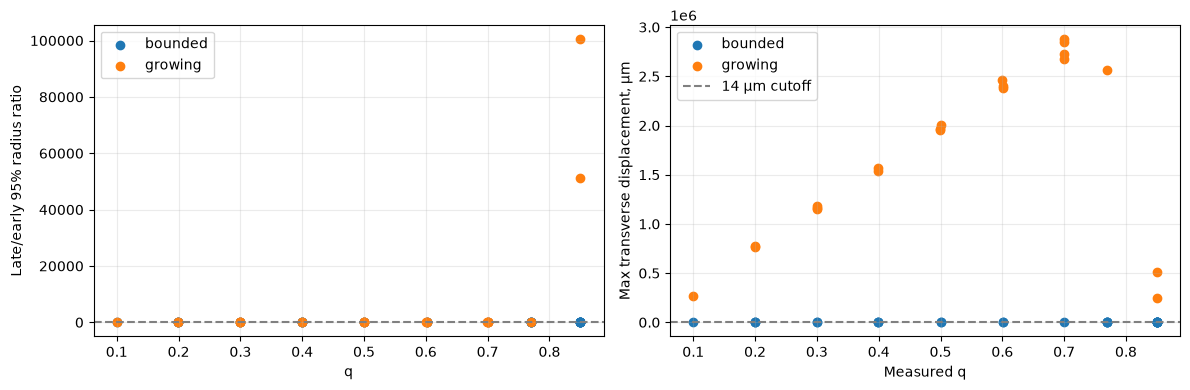

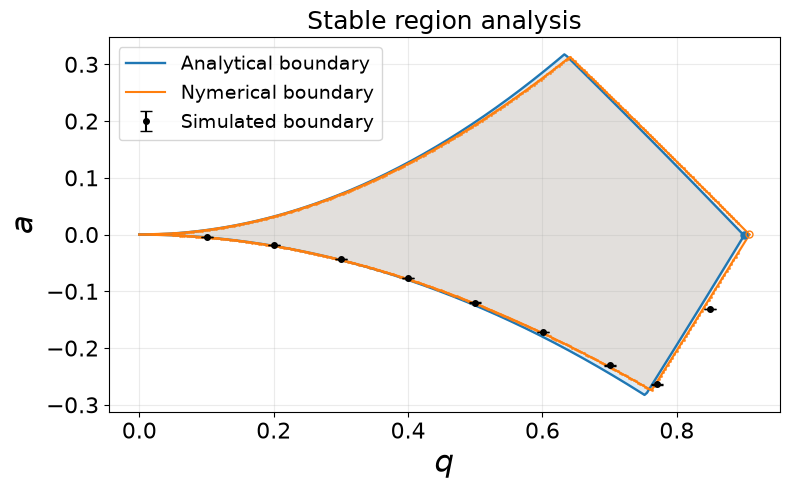

Exact MD geometry was not present in the Part-I sampled grid; stable regions were rebuilt from the saved MD benchmark parameters (alpha=0.629994, theta=3.08235 rad).
Reprocessed MD tables and figures saved to: C:\Users\User\Desktop\ARTEM\Sion\tests\supplementary\stability_verification_results\postprocessed_radius_14um
Total geometry/resolution cases: 70; successful: 70


rmse_lower_a                   rmse_upper_a                    \
               mean   median      max         mean   median      max   
level                                                                  
coarse      0.01025  0.00803  0.03250      0.00589  0.00555  0.01156   
fine        0.00922  0.00763  0.01881      0.00575  0.00547  0.01104   

       rmse_combined_a                   max_abs_error_a                    \
                  mean   median      max            mean   median      max   
level                                                                        
coarse         0.00846  0.00698  0.02322         0.02748  0.01750  0.12897   
fine           0.00775  0.00665  0.01519         0.02778  0.01752  0.12908   

       region_iou                    
             mean   median      max  
level                                
coarse    0.96365  0.96408  0.97098  
fine      0.96455  0.96416  0.97587

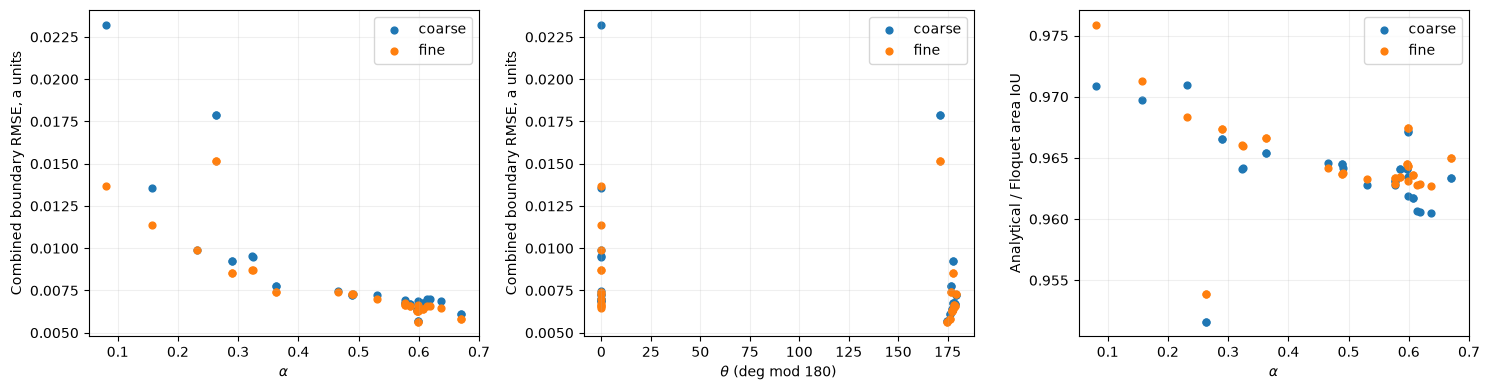

,geometry_id,alpha,theta_rad,qcrit_analytic,qcrit_floquet,qcrit_delta,qcrit_bracket_width
35,0,0.157256,0.000000,0.898979,0.907759,0.008779,0.000702
36,1,0.636110,0.000000,0.898979,0.907759,0.008779,0.000702
37,2,0.597903,0.000000,0.898979,0.907759,0.008779,0.000702
38,3,0.262606,2.983247,0.916953,0.907998,-0.008955,0.000716
39,4,0.596296,3.088973,0.899830,0.907914,0.008084,0.000703
40,5,0.577552,3.111942,0.899258,0.908040,0.008782,0.000703
41,6,0.598926,3.049353,0.901617,0.908309,0.006692,0.000704
42,7,0.670610,3.071676,0.900316,0.907701,0.007385,0.000703
43,8,0.606981,3.103133,0.899424,0.908207,0.008783,0.000703
44,9,0.262610,2.983249,0.916952,0.907998,-0.008955,0.000716


Floquet qcrit: mean absolute difference = 0.0083921 ; maximum absolute difference = 0.0089546


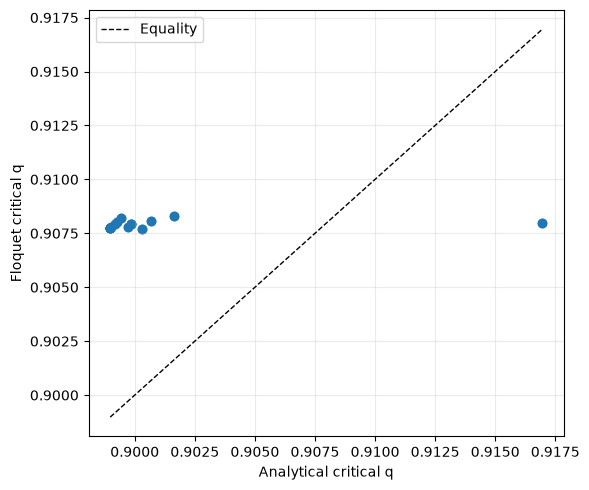

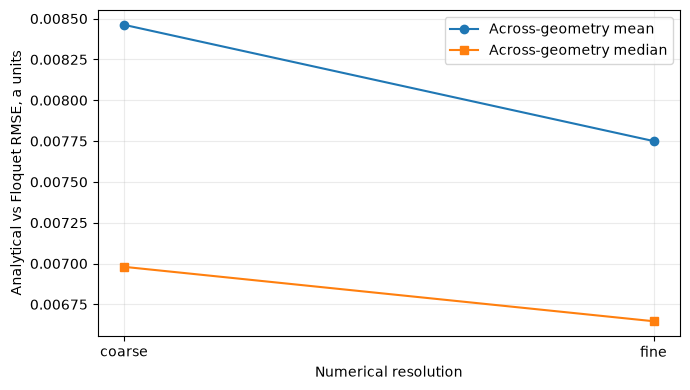

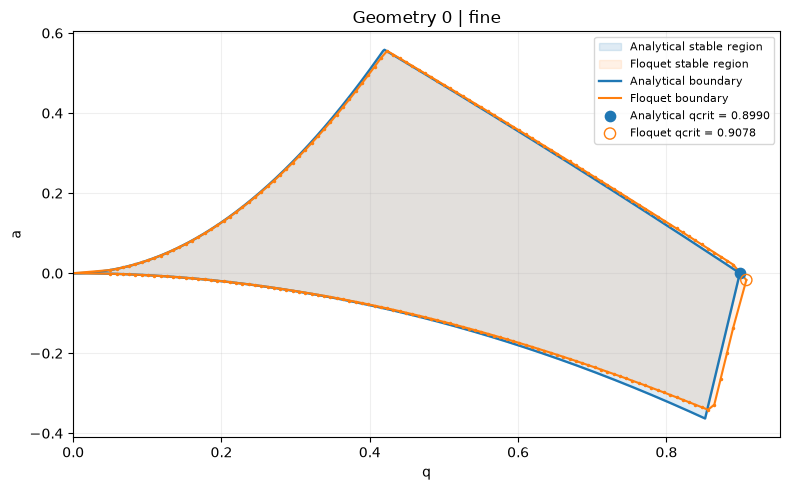

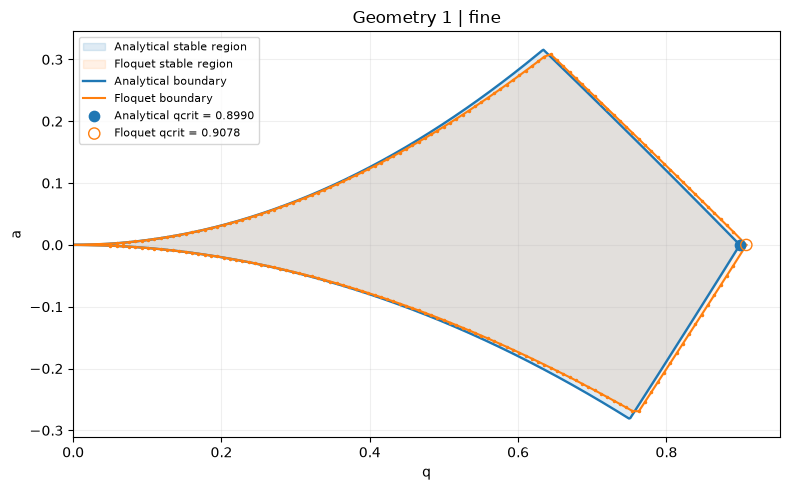

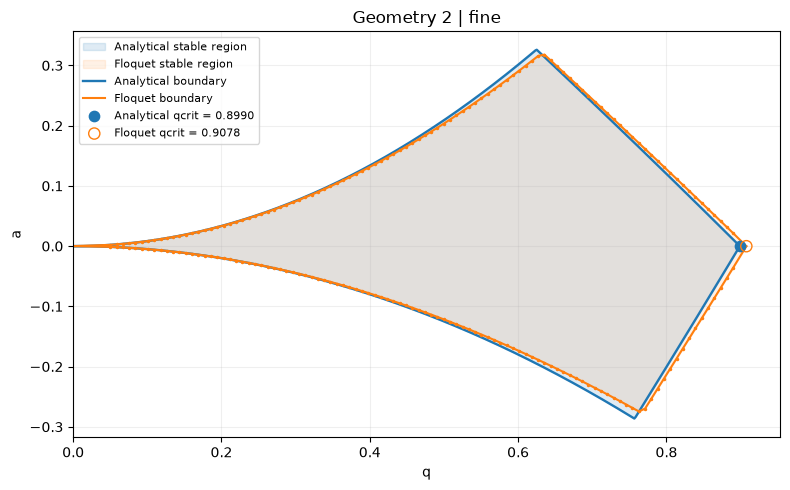

In [41]:
# Run all definition cells above with POSTPROCESS_ONLY = True.
# Change MD_MAX_BOUNDED_RADIUS_UM in Cell 1 and rerun this cell to test another cutoff.


def load_saved_md_attempts():
    """Prefer per-q checkpoints; fall back to a combined CSV, then to .npz-only data."""
    checkpoints = sorted((results_dir / 'md_runs').glob('q_*/attempts_partial.csv'))
    parts = []
    for file in checkpoints:
        piece = pd.read_csv(file, dtype={'q_label': str})
        piece['q_label'] = file.parent.name[2:]  # authoritative q key from saved directory
        parts.append(piece)
    combined_path = results_dir / 'md_stability_summary.csv'
    fallback_path = combined_path if combined_path.exists() else results_dir/'md_results_partial.csv'
    if fallback_path.exists():
        combined = pd.read_csv(fallback_path, dtype={'q_label': str})
        if parts:
            q_present = set(pd.concat(parts)['q_label'].astype(str))
            combined = combined[~combined['q_label'].astype(str).isin(q_present)]
        if not combined.empty:
            parts.append(combined)
    if parts:
        df = pd.concat(parts, ignore_index=True)
        # Recover the combined CSV if it was never written. Do not overwrite an original.
        if not combined_path.exists():
            df.to_csv(combined_path, index=False)
            print('Restored missing combined MD CSV:', combined_path)
        print(f'Loaded {len(df)} attempt records from {len(checkpoints)} per-q checkpoints and/or combined CSV')
        return df

    trajectories = sorted((results_dir/'md_runs').glob('q_*/trajectory_*.npz'))
    records = []
    for file in trajectories:
        q_key = file.parent.name[2:]
        match = re.search(r'attempt_(\d+)_', file.stem)
        if not match:
            continue
        with np.load(file, allow_pickle=False) as data:
            dc = np.asarray(data['dc_volts'], float)
            vrf = float(data['Vrf'])
        template = border_stability_configurations.get(q_key, {}).get('dc_set_border')
        if template is not None:
            template = np.asarray(template, float)
        m = float(np.dot(dc,template)/np.dot(template,template)) if template is not None else np.nan
        records.append({'q_label':q_key, 'attempt':int(match.group(1)),
                        'dc_multiplier':m, 'scan_stage':'npz_only',
                        'Vrf_V':vrf, 'dc_set_V':json.dumps(dc.tolist()),
                        'status':'ok', 'classification':'unknown',
                        'a':np.nan, 'q':np.nan, 'alpha':np.nan, 'theta_rad':np.nan,
                        'sion_is_stable':False, 'floquet_is_stable':False,
                        'floquet_evaluated':False, 'trajectory_npz':str(file)})
    df = pd.DataFrame(records)
    if not df.empty:
        print(f'Only trajectory NPZ files found: recovered {len(df)} attempts. '
              'Model parameters (a,q) require SION recomputation.')
    return df


def saved_trajectory_path(row):
    """Locate the exact trajectory file, despite moving the saved results directory."""
    d = results_dir/'md_runs'/f"q_{row['q_label']}"
    explicit = row.get('trajectory_npz')
    if isinstance(explicit,str) and explicit.strip():
        p = Path(explicit)
        if p.is_file():
            return p
        if (d/p.name).is_file():
            return d/p.name
    dump = row.get('dump_path')
    if isinstance(dump,str) and dump.strip():
        name = Path(dump).name
        if name.startswith('positions_'):
            exact = d/('trajectory_'+name[len('positions_'):-len('.txt')]+'.npz')
            if exact.is_file():
                return exact
    attempt = pd.to_numeric(row.get('attempt'), errors='coerce')
    if pd.notna(attempt):
        match = sorted(d.glob(f'trajectory_*_attempt_{int(attempt):03d}_*.npz'))
        if len(match)==1:
            return match[0]
    return None


def reclassify_saved_md(df):
    df = df.copy()
    df['q_label'] = df['q_label'].astype(str)
    df['classification_original'] = df.get('classification', pd.Series(index=df.index, dtype=object))
    df['reclassification_status'] = 'not_checked'
    df['trajectory_npz'] = df.get('trajectory_npz', pd.Series(index=df.index, dtype=object))
    for idx, row in df.iterrows():
        file = saved_trajectory_path(row)
        if file is None:
            df.at[idx,'reclassification_status'] = 'trajectory_missing_or_ambiguous'
            if row.get('status') == 'ok':
                df.at[idx,'classification'] = 'trajectory_unavailable'
            continue
        try:
            with np.load(file,allow_pickle=False) as data:
                stats = trajectory_metrics(data['steps'], data['xyz_m'],
                                           data['reference_m'], data['initial_m'])
            for key,val in stats.items():
                if isinstance(val, list):
                    val = json.dumps(val)
                df.at[idx,key] = val
            df.at[idx,'status'] = 'ok'
            df.at[idx,'trajectory_npz'] = str(file)
            df.at[idx,'reclassification_status'] = 'recomputed'
        except Exception as exc:
            df.at[idx,'reclassification_status'] = f'{type(exc).__name__}: {exc}'
    return df


def restore_model_parameters_for_npz_only(df):
    """Optional: SION-only recalculation if no checkpoint has saved a and q."""
    missing = (df['a'].isna() & df['reclassification_status'].eq('recomputed')
               & df.get('scan_stage',pd.Series('',index=df.index)).eq('npz_only'))
    if not missing.any() or not REBUILD_MODEL_FROM_NPZ_ONLY:
        return df
    if sn is None:
        print('SION is not installed. a/q cannot be restored from trajectories alone.')
        return df
    for q_key, part in df[missing].groupby('q_label'):
        try:
            vrf = float(part.iloc[0]['Vrf_V'])
            s, _, _, _ = make_md_geometry(vrf)
            for idx, row in part.iterrows():
                file = Path(row['trajectory_npz'])
                with np.load(file,allow_pickle=False) as data:
                    dc = np.asarray(data['dc_volts'],float)
                    reference = np.asarray(data['reference_m'],float)
                pred = predict_for_dc(s,vrf,dc,reference)
                for k,v in pred.items():
                    df.at[idx,k] = v
        except Exception as exc:
            print(f'Could not recompute SION values for q={q_key}: {exc}')
    return df


def recover_and_analyze_saved_results():
    if not results_dir.exists():
        raise FileNotFoundError(f'Saved results directory does not exist: {results_dir}')
    POSTPROCESS_OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
    df = load_saved_md_attempts()
    if df.empty:
        print('No MD records found. Expected md_runs/q_*/attempts_partial.csv '
              'or md_runs/q_*/trajectory_*.npz under:',results_dir)
        return pd.DataFrame(), pd.DataFrame()
    df = reclassify_saved_md(df)
    df = restore_model_parameters_for_npz_only(df)
    for flag in ['sion_is_stable','floquet_is_stable','floquet_evaluated']:
        if flag not in df:
            df[flag] = False
        df[flag] = (df[flag].astype(str).str.strip().str.lower()
                    .isin(['true','1','yes']))
    for name in ['a','q','dc_multiplier','alpha','theta_rad']:
        if name not in df:
            df[name] = np.nan
        df[name] = pd.to_numeric(df[name],errors='coerce')
    df.to_csv(POSTPROCESS_OUTPUT_DIR/'md_stability_summary.csv',index=False)
    counts = df['reclassification_status'].value_counts()
    print('Recovered trajectory status:',counts.to_dict())
    print('MD classification (new cutoff):',df['classification'].value_counts().to_dict())
    changed = df[df['classification'] != df['classification_original']]
    print(f'Classification changed for {len(changed)} attempt(s):')
    if len(changed):
        display(changed[['q_label','attempt','dc_multiplier','classification_original',
                         'classification','max_radius_um','r95_ratio']])
    # Recalculate agreement: inconclusive/error is NOT counted as stable or unstable.
    verdict = df[['q_label','attempt','dc_multiplier','a','q','status',
                  'classification','sion_is_stable','floquet_is_stable',
                  'floquet_evaluated']].copy()
    verdict['md_is_bounded'] = verdict['classification'].map({'bounded':True,'growing':False})
    verdict['sion_agrees_with_md'] = [bool(p)==bool(m) if pd.notna(m) else np.nan
            for p,m in zip(verdict['sion_is_stable'],verdict['md_is_bounded'])]
    verdict['floquet_agrees_with_md'] = [bool(p)==bool(m) if pd.notna(m) and evaluated else np.nan
            for p,m,evaluated in zip(verdict['floquet_is_stable'],
                                      verdict['md_is_bounded'],verdict['floquet_evaluated'])]
    verdict.to_csv(POSTPROCESS_OUTPUT_DIR/'verification_agreement.csv',index=False)
    summary = summarize_md_bracket(df)
    summary['reprocessed_bracket_status'] = np.select(
        [summary['bracket_rel_width'].le(MD_REL_BRACKET_TOL),
         summary['bracket_rel_width'].notna()],
        ['bracket_within_tolerance', 'bracket_above_tolerance'],
        default='no_complete_bracket')
    summary.to_csv(POSTPROCESS_OUTPUT_DIR/'md_bracket_summary.csv',index=False)
    print('Reprocessed bracket status:',summary['reprocessed_bracket_status'].value_counts().to_dict())
    display(summary)
    fig, axs = plt.subplots(1,2,figsize=(12,4))
    for label, grp in df[df['status']=='ok'].groupby('classification'):
        axs[0].scatter(grp['q'],grp['r95_ratio'],label=label)
        axs[1].scatter(grp['q'],grp['max_radius_um'],label=label)
    axs[0].axhline(3,color='gray',ls='--')
    axs[0].set(xlabel='q',ylabel='Late/early 95% radius ratio')
    axs[1].axhline(MD_MAX_BOUNDED_RADIUS_UM,color='gray',ls='--',
                   label=f'{MD_MAX_BOUNDED_RADIUS_UM:g} µm cutoff')
    axs[1].set(xlabel='Measured q',ylabel='Max transverse displacement, µm')
    for ax in axs:
        ax.grid(alpha=.25); ax.legend()
    fig.tight_layout()
    fig.savefig(POSTPROCESS_OUTPUT_DIR/'md_radius_comparison.png',dpi=200)
    plt.show()
    if summary['a_bracket_midpoint'].notna().any() or summary['a_bounded'].notna().any():
        plot_md_boundary_comparison(summary, save_path=POSTPROCESS_OUTPUT_DIR/'md_bracket_comparison.png',
                                    md_attempts=df)
    else:
        print('No a–q diagram: a/q were not saved; supply checkpoint CSVs or SION for model-only reconstruction.')
    (POSTPROCESS_OUTPUT_DIR/'postprocess_configuration.json').write_text(json.dumps({
        'radius_limit_um':MD_MAX_BOUNDED_RADIUS_UM,
        'min_growth_radius_um':MD_MIN_GROWTH_RADIUS_UM,
        'early_late_fraction':MD_EARLY_LATE_FRACTION,
        'saved_data_directory':str(results_dir),
        'reprocessed_utc':datetime.now(timezone.utc).isoformat()}, indent=2))
    print('Reprocessed MD tables and figures saved to:',POSTPROCESS_OUTPUT_DIR)
    return df, summary


if REPROCESS_SAVED_DATA:
    recovered_md_df, recovered_md_brackets = recover_and_analyze_saved_results()

    # Part I can be redrawn solely from previously saved CSV/NPZ files.
    if RECOVERY_SAVE_FLOQUET_PLOTS:
        fp = results_dir/'floquet_boundary_summary.csv'
        if fp.exists():
            floquet_saved = pd.read_csv(fp, dtype={'geometry_id':str})
            curves_saved = {}
            for row in floquet_saved.itertuples():
                p = results_dir/f'floquet_geometry_{row.geometry_id}_{row.level}.npz'
                if p.exists():
                    with np.load(p,allow_pickle=False) as f:
                        curves_saved[(str(row.geometry_id),row.level)] = {k:f[k] for k in f.files}
            if curves_saved:
                analyze_floquet(floquet_saved,curves_saved)
            else:
                print('Part I summary exists, but curve NPZ files are unavailable; skipping diagrams.')
        else:
            print('No saved Floquet CSV; skipping Part I figures.')
